## Index Computation: Multivariable ##  
Bestimme Index analog zu anderen Berechnungen, aber gebe als Input mehrere Variablen gleichzeitig um einen multivariablen Index zu erhalten.

In [1]:
from pathlib import Path
import datetime as dt

import geopandas as gpd
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import zarr
import pandas as pd

from data_registry import Bibliography
from domino.core import LaggedAnalyser, PatternFilter, IndexGenerator
from domino.prediction import PredictionTest
from domino import agg
from coords_workflow_utils import PreparedCoordsLoader, NUTSMaskTools
from scipy.stats import ks_2samp

import cartopy.crs as ccrs
import cmocean.cm as cm

**Configuration**

In [2]:
# -----CONFIGURATION----------
bib = Bibliography(Path("data"))
# bib.add("energy", "WON", "daily", "subcountry", "prepared/WON_daily_subcountry_prepared_DJF.csv")
bib.add("energy", "SPV", "daily", "subcountry", "prepared/SPV_daily_subcountry_prepared_DJF.csv")
# bib.add("atmosphere", "mean_sea_level_pressure", "daily", "subcountry", "ERA5/prepared/DJF_anom/mean_sea_level_pressure")
# bib.add("atmosphere", "geopotential", "daily", "subcountry", "ERA5/prepared/DJF_anom/geopotential500")
# bib.add("atmosphere", "wind_speed", "daily", "subcountry", "ERA5/prepared/DJF_anom/wind_speed")
# bib.add('atmosphere', 'total_column_water_vapour', 'daily', 'global', 'ERA5/prepared/DJF_anom/total_column_water_vapour')
# bib.add('atmosphere', '2m_temperature', 'daily', 'global', 'ERA5/prepared/DJF_anom/2m_temperature')
bib.add('atmosphere', 'relative_humidity', 'daily', 'global', 'ERA5/prepared/DJF_anom/relative_humidity700')

# -----VARIABLES-----------
erstelldatum = dt.date.today()
lags = [-4,-3,-2,-1,0] # [-6, -5, -4, -3, -2, -1, 0]
region_ziel = "Norddeutschland"  # region der ziel variablen
region_prec = "EUROPE"  # welche Daten werden als precursor verwendet
timeperiod = "1979-2025"  # zeitraum der analysierten daten
quant = 0.1  # welches quantile => def extreme event
extreme_event = "l"  # l=low 0.1, h=high 0.9

# -----OPTIONS-----------
use_deseasonalization = True  # Deseasonalisierung durchführen?
deseasonalization_agg = "dayofyear"  # Aggregationsmethode: 'dayofyear', 'month', etc.
deseasonalization_smooth = 30  # Glättungsfenster für deseasonalization
use_bootstrap = False  # Bootstrap Significance Test durchführen?
bootstrap_num = 100  # Anzahl Bootstrap-Samples
bootstrap_p = 0.05  # Signifikanzniveau
min_connected_size = 10

energy_entries = bib.get_by_category("energy")
atm_entries = bib.get_by_category("atmosphere")

## Data Prep

In [3]:
# load event and precursor data to set up analyser
energy_entry = energy_entries[0]
atm_entry = atm_entries[0]

event = PreparedCoordsLoader.load_energy_event_from_prepared(
    path=energy_entry.path,
    energy_name=energy_entry.name,
    region_ziel=region_ziel,
    quant=quant,
    extreme_event=extreme_event,
)
print(event)

<xarray.DataArray 'SPV' (time: 4211)> Size: 34kB
array([0, 0, 0, ..., 0, 0, 0], shape=(4211,))
Coordinates:
  * time     (time) datetime64[us] 34kB 1979-01-01 1979-01-02 ... 2025-02-28


In [4]:
# lade einzelne atm variablen als xr.Dataset
atm_entry = atm_entries[0]
ATM_NAME = atm_entry.name # "geopotential", "mean_sea_level_pressure", "2m_temperature"
LEVEL = '' # '' for non level data
WEATHERBENCH_DAILY_PATH = atm_entry.path
print(WEATHERBENCH_DAILY_PATH)
print("[INFO] Merging all years into a single dataset...")
files = sorted(WEATHERBENCH_DAILY_PATH.glob("*.nc")) #era5_daily_
ds_all = xr.open_mfdataset(
    files, combine="by_coords",
    chunks={"time": 50, "latitude":50, "longitude":50} # changed time from 365 for deseason
).load()
print("[INFO] Loaded and merged WeatherBench dailymeans dataset")

ds_djf = ds_all.sel(time=ds_all.time.dt.month.isin([12, 1, 2]))#ds_all.sel(init_time=ds_all.init_time.dt.month.isin([12, 1, 2]))
ds_all = ds_djf
month_idx = '_DJF'
del ds_djf
# ds_msl = ds_all
ds_wv = ds_all

data\ERA5\prepared\DJF_anom\relative_humidity700
[INFO] Merging all years into a single dataset...
[INFO] Loaded and merged WeatherBench dailymeans dataset


In [5]:
# # lade einzelne atm variablen als xr.Dataset
# atm_entry = atm_entries[1]
# ATM_NAME = atm_entry.name # "geopotential", "mean_sea_level_pressure", "2m_temperature"
# LEVEL = '' # '' for non level data
# WEATHERBENCH_DAILY_PATH = atm_entry.path
# print(WEATHERBENCH_DAILY_PATH)
# print("[INFO] Merging all years into a single dataset...")
# files = sorted(WEATHERBENCH_DAILY_PATH.glob("*.nc")) #era5_daily_
# ds_all = xr.open_mfdataset(
#     files, combine="by_coords",
#     chunks={"time": 50, "latitude":50, "longitude":50} # changed time from 365 for deseason
# ).load()
# print("[INFO] Loaded and merged WeatherBench dailymeans dataset")

# ds_djf = ds_all.sel(time=ds_all.time.dt.month.isin([12, 1, 2]))#ds_all.sel(init_time=ds_all.init_time.dt.month.isin([12, 1, 2]))
# ds_all = ds_djf
# month_idx = '_DJF'
# del ds_djf
# # ds_z500 = ds_all
# ds_t2 = ds_all

In [6]:
# # lade einzelne atm variablen als xr.Dataset
# atm_entry = atm_entries[2]
# ATM_NAME = atm_entry.name # "geopotential", "mean_sea_level_pressure", "2m_temperature"
# LEVEL = '' # '' for non level data
# WEATHERBENCH_DAILY_PATH = atm_entry.path
# print(WEATHERBENCH_DAILY_PATH)
# print("[INFO] Merging all years into a single dataset...")
# files = sorted(WEATHERBENCH_DAILY_PATH.glob("*.nc")) #era5_daily_
# ds_all = xr.open_mfdataset(
#     files, combine="by_coords",
#     chunks={"time": 50, "latitude":50, "longitude":50} # changed time from 365 for deseason
# ).load()
# print("[INFO] Loaded and merged WeatherBench dailymeans dataset")

# ds_djf = ds_all.sel(time=ds_all.time.dt.month.isin([12, 1, 2]))#ds_all.sel(init_time=ds_all.init_time.dt.month.isin([12, 1, 2]))
# ds_all = ds_djf
# month_idx = '_DJF'
# del ds_djf
# ds_ws = ds_all

In [7]:
# # rechne longitudes bei allen um
# ds_ws = ds_ws.assign_coords(
#     longitude=((ds_ws.longitude + 180) % 360) - 180
# ).sortby("longitude")
# ds_msl = ds_msl.assign_coords(
#     longitude=((ds_msl.longitude + 180) % 360) - 180
# ).sortby("longitude")
# ds_z500 = ds_z500.assign_coords(
#     longitude=((ds_z500.longitude + 180) % 360) - 180
# ).sortby("longitude")
ds_wv = ds_wv.assign_coords(
    longitude=((ds_wv.longitude + 180) % 360) - 180
).sortby("longitude")
# ds_t2 = ds_t2.assign_coords(
#     longitude=((ds_t2.longitude + 180) % 360) - 180
# ).sortby("longitude")

**Füge Daten zu einem xarray zusammen**

In [8]:
ds_all = ds_wv #xr.merge([ds_wv, ds_t2])#xr.merge([ds_msl, ds_z500, ds_ws])

In [9]:
ds_all

<xarray.Dataset> Size: 3GB
Dimensions:            (time: 3971, latitude: 289, longitude: 561)
Coordinates:
  * time               (time) datetime64[ns] 32kB 1979-01-01 ... 2022-12-31
    level              (time) int64 32kB 700 700 700 700 700 ... 700 700 700 700
    dayofyear          (time) int64 32kB 1 2 3 4 5 6 ... 360 361 362 363 364 365
  * latitude           (latitude) float32 1kB 84.0 83.75 83.5 ... 12.25 12.0
  * longitude          (longitude) float32 2kB -90.0 -89.75 -89.5 ... 49.75 50.0
Data variables:
    relative_humidity  (time, latitude, longitude) float32 3GB nan ... 0.7852

## Analyser

In [10]:
# split into training and test data
training_predictor=ds_all.sel(time=slice('1980','2010'))
training_event=event.sel(time=slice('1980','2010'))
test_predictor=ds_all.sel(time=slice('2011','2022'))
test_event=event.sel(time=slice('2011','2022')) 

In [11]:
analyser = LaggedAnalyser(event=training_event, variables=training_predictor)
analyser.lag_variables(lags, offset_unit='days', mode='past')

In [12]:
composites = xr.open_dataset(f'data//domino_output_coords_weatherbench/{energy_entry.name}/{energy_entry.name}-{extreme_event}_{region_ziel}_{ATM_NAME}_{region_prec}_1979_lags_{"_".join(map(str, lags))}_composites_coords_deseasonalized_DJF_anom.nc')#analyser.compute_composites(as_anomaly=True)
lagged_means = xr.open_dataset(f'data//domino_output_coords_weatherbench/{energy_entry.name}/{energy_entry.name}-{extreme_event}_{region_ziel}_{ATM_NAME}_{region_prec}_1979_lags_{"_".join(map(str, lags))}_lagged-means_coords_deseasonalized_DJF_anom.nc')

In [13]:
analyser.composites = composites
analyser.lagged_means = lagged_means
analyser.composites_are_anomaly = True
analyser.composite_func = (agg.mean_ds, agg.cat_occ_ds)

In [14]:
# composite_pattern=composites.sel(index_val=1,lag=-9)
# vars = list(composite_pattern.data_vars)
# fig, axes = plt.subplots(
#     1, len(vars),
#     figsize=(5 * len(vars), 4),
#     subplot_kw=dict(projection=ccrs.PlateCarree())
# )

# for ax, var in zip(axes, vars):
#     data = composite_pattern[var]
#     vabs = max(abs(data.min().item()), abs(data.max().item()))
#     data.plot(
#         ax=ax,
#         transform=ccrs.PlateCarree(),
#         vmin=-vabs,
#         vmax=vabs,
#         cmap="RdBu_r",
#         add_colorbar=True
#     )
#     ax.coastlines()
#     ax.set_title(var)

# plt.suptitle(f"Composite Pattern for Lag 0 - {extreme_event}-event - DJF", fontsize=16)
# plt.tight_layout()
# plt.subplots_adjust(top=0.9)

## Pattern Filter

In [15]:
bootstrap = xr.open_dataset(f'data//domino_output_coords_weatherbench/{energy_entry.name}/100/{energy_entry.name}-{extreme_event}_{region_ziel}_{ATM_NAME}_{region_prec}_1979_lags_-6_-3_0_bootstrap-composites_deseasonalized_DJF_anom.nc')

In [16]:
analyser.composite_sigs = bootstrap

In [17]:
# S=analyser.bootstrap_significance(2,p=0.1)
# masked_composite=composites.where(S==1)

In [18]:
print(analyser.__dict__.keys())

dict_keys(['event', 'variables', '_lagged_variables', 'lagged_means', '_derived_variables', 'deseasonalisers_', 'composite_mask', 'boot_indices', 'offset_unit', 'composites', 'composites_are_anomaly', 'composite_func', 'composite_sigs'])


In [26]:
print(type(analyser.composite_sigs))
print(analyser.composite_sigs.dims)
print(analyser.composite_sigs.data_vars)

<class 'xarray.core.dataset.Dataset'>
FrozenMappingWarningOnValuesAccess({'lag': 3, 'index_val': 2, 'latitude': 289, 'longitude': 561})
Data variables:
    relative_humidity  (lag, index_val, latitude, longitude) float32 4MB ...


In [20]:
# composite_pattern=masked_composite.sel(index_val=1,lag=-9)
# vars = list(composite_pattern.data_vars)
# fig, axes = plt.subplots(
#     1, len(vars),
#     figsize=(5 * len(vars), 4),
#     subplot_kw=dict(projection=ccrs.PlateCarree())
# )

# for ax, var in zip(axes, vars):
#     data = composite_pattern[var]
#     vabs = max(abs(data.min().item()), abs(data.max().item()))
#     data.plot(
#         ax=ax,
#         transform=ccrs.PlateCarree(),
#         vmin=-vabs,
#         vmax=vabs,
#         cmap="RdBu_r",
#         add_colorbar=True
#     )
#     ax.coastlines()
#     ax.set_title(var)

# plt.suptitle(f"Masked Composite Pattern for Lag 0 - {extreme_event}-event - DJF", fontsize=16)
# plt.tight_layout()
# plt.subplots_adjust(top=0.9)

In [21]:
# # lade bootstrap composites aus alten berechnungen
# bt_composite_msl = xr.open_dataset(f"data/domino_output_coords_weatherbench/WON/100/WON-{extreme_event}_Norddeutschland_mean_sea_level_pressure_EUROPE_1979_lags_-6_-3_0_bootstrap-composites_deseasonalized_DJF_anom.nc")
# bt_composite_z500 = xr.open_dataset(f"data/domino_output_coords_weatherbench/WON/100/WON-{extreme_event}_Norddeutschland_geopotential_EUROPE_1979_lags_-6_-3_0_bootstrap-composites_deseasonalized_DJF_anom.nc")
# bt_composite_ws = xr.open_dataset(f"data/domino_output_coords_weatherbench/WON/100/WON-{extreme_event}_Norddeutschland_wind_speed_EUROPE_1979_lags_-6_-3_0_bootstrap-composites_deseasonalized_DJF_anom.nc")

In [22]:
# bt_composite_msl = bt_composite_msl.assign_coords(
#     longitude=((bt_composite_msl.longitude + 180) % 360) - 180
# ).sortby("longitude")
# bt_composite_z500 = bt_composite_z500.assign_coords(
#     longitude=((bt_composite_z500.longitude + 180) % 360) - 180
# ).sortby("longitude")
# bt_composite_ws = bt_composite_ws.assign_coords(
#     longitude=((bt_composite_ws.longitude + 180) % 360) - 180
# ).sortby("longitude")
# bt_all = xr.merge([bt_composite_msl, bt_composite_z500, bt_composite_ws])

In [23]:
# composite_pattern=masked_composite.sel(index_val=1,lag=-6)
# vars = list(composite_pattern.data_vars)
# fig, axes = plt.subplots(
#     1, len(vars),
#     figsize=(5 * len(vars), 4),
#     subplot_kw=dict(projection=ccrs.PlateCarree())
# )

# for ax, var in zip(axes, vars):
#     data = composite_pattern[var]
#     vabs = max(abs(data.min().item()), abs(data.max().item()))
#     data.plot(
#         ax=ax,
#         transform=ccrs.PlateCarree(),
#         vmin=-vabs,
#         vmax=vabs,
#         cmap="RdBu_r",
#         add_colorbar=True
#     )
#     ax.coastlines()
#     ax.set_title(var)

# plt.suptitle(f"Masked Composite Pattern for Lag 0 - {extreme_event}-event - DJF", fontsize=16)
# plt.tight_layout()
# plt.subplots_adjust(top=0.9)

In [24]:
PF = PatternFilter(analyser=analyser)
thresh_dict=dict(relative_humidity=0.01) #mean_sea_level_pressure=250,geopotential=300,wind_speed=2.5, relative_humidity=0.05 total_column_water_vapour=1.

def abs_amplitude_over_threshold(val_ds,thresh_dict):
    return abs(val_ds)>xr.Dataset(thresh_dict)

PF.apply_value_mask(abs_amplitude_over_threshold,thresh_dict,mode='intersection')
mask1=PF.get_mask() #retrieve the new mask for plotting later.

In [25]:
print(masked_composite)

NameError: name 'masked_composite' is not defined

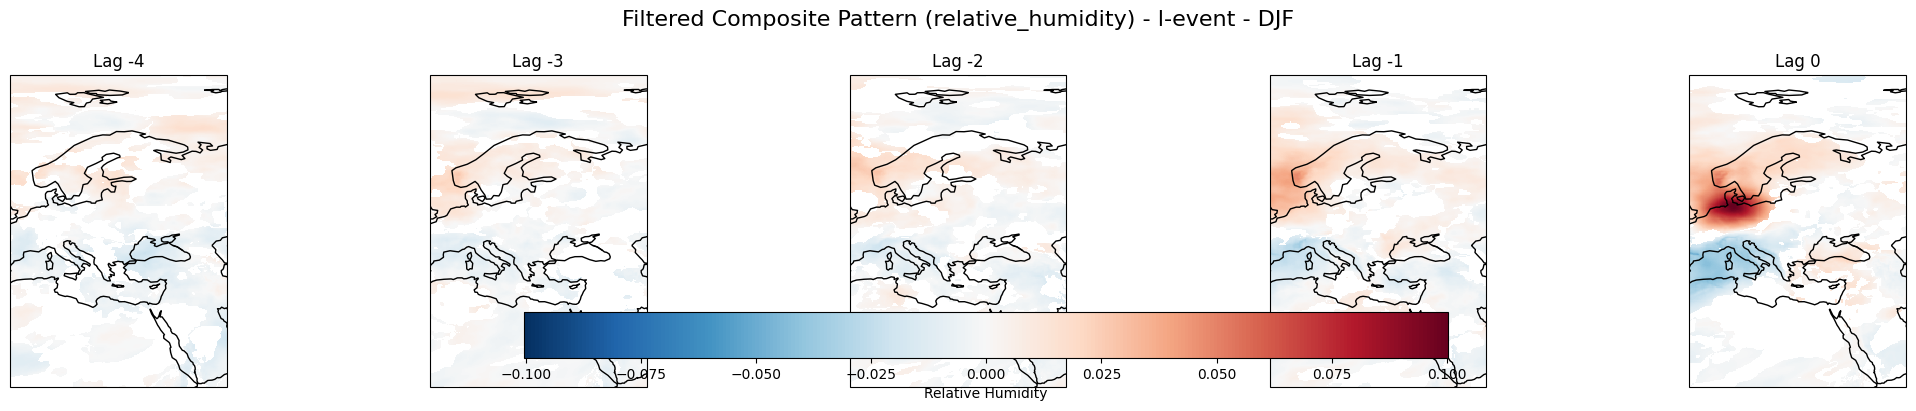

In [ ]:
mask1_composite = masked_composite#.where(mask1 == 1)

# Nur index_val auswählen, alle Lags behalten
composite_pattern = mask1_composite.sel(index_val=1)

var = "relative_humidity"

lags = composite_pattern.lag.values

fig, axes = plt.subplots(
    1, len(lags),
    figsize=(4.5 * len(lags), 4),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

axes = np.atleast_1d(axes)

# gemeinsame Farbskala über alle Lags
data_all = composite_pattern[var]
vabs = np.nanmax(np.abs(data_all.values))

for ax, lag in zip(axes, lags):

    data = composite_pattern[var].sel(lag=lag)

    im = data.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap="RdBu_r",
        vmin=-vabs,
        vmax=vabs,
        add_colorbar=False,
    )

    ax.coastlines()
    ax.set_title(f"Lag {lag}")

# gemeinsame Colorbar
cbar = fig.colorbar(
    im,
    ax=axes,
    orientation="horizontal",
    pad=0.08,
    shrink=0.8
)
cbar.set_label("Relative Humidity")

plt.suptitle(
    f"Filtered Composite Pattern ({var}) - {extreme_event}-event - DJF",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
stop

NameError: name 'stop' is not defined

## Index Generator

In [ ]:
# IG = IndexGenerator()

In [ ]:
# index_slices=[dict(index_val=1,lag=0)]

# SON_variables=xr.align(analyser.variables,analyser.event)[0]

In [ ]:
# SON_variables

<xarray.Dataset> Size: 5GB
Dimensions:                  (time: 2798, latitude: 289, longitude: 561)
Coordinates:
  * time                     (time) datetime64[us] 22kB 1980-01-01 ... 2010-1...
    dayofyear                (time) int64 22kB 1 2 3 4 5 ... 361 362 363 364 365
    level                    (time) int64 22kB 500 500 500 500 ... 500 500 500
  * latitude                 (latitude) float32 1kB 84.0 83.75 ... 12.25 12.0
  * longitude                (longitude) float32 2kB -90.0 -89.75 ... 49.75 50.0
Data variables:
    mean_sea_level_pressure  (time, latitude, longitude) float32 2GB 1.613e+0...
    geopotential             (time, latitude, longitude) float32 2GB 1.003e+0...
    wind_speed               (time, latitude, longitude) float32 2GB -4.433 ....

In [ ]:
# # masked_composite_chunks = masked_composite.chunk({'time': 100})
# SON_variables_chunks = SON_variables.chunk({'time': 100})

# indices=IG.generate(masked_composite,SON_variables_chunks,dim='time',slices=index_slices)

In [ ]:
# len(indices.time)

2798

In [ ]:
# event training
# event_training = event.sel(time=slice('1980','2010'))

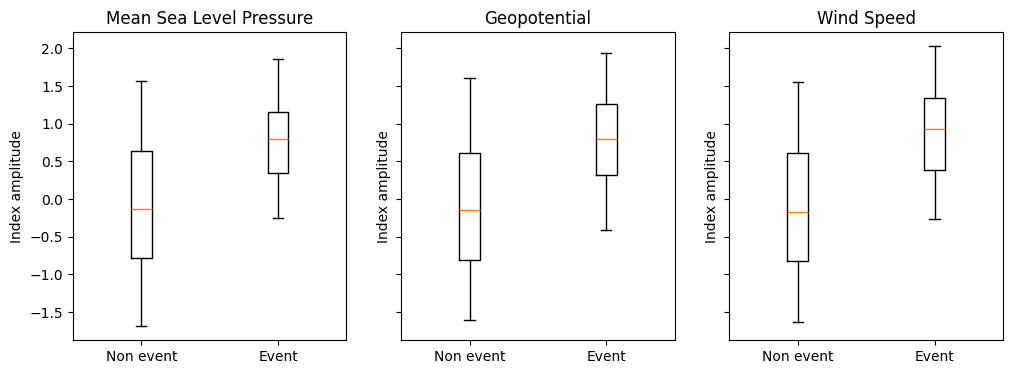

In [ ]:
# fig,ax=plt.subplots(1,3, figsize=(12,4), sharey=True)

# ax[0].boxplot(indices.mean_sea_level_pressure_index_val1_lag0[event_training==0].values,positions=[0],whis=[5,95],showfliers=False)
# ax[0].boxplot(indices.mean_sea_level_pressure_index_val1_lag0[event_training==1].values,positions=[1],whis=[5,95],showfliers=False)
# ax[0].set_title('Mean Sea Level Pressure')

# ax[1].boxplot(indices.geopotential_index_val1_lag0[event_training==0].values,positions=[0],whis=[5,95],showfliers=False)
# ax[1].boxplot(indices.geopotential_index_val1_lag0[event_training==1].values,positions=[1],whis=[5,95],showfliers=False)
# ax[1].set_title('Geopotential')

# ax[2].boxplot(indices.wind_speed_index_val1_lag0[event_training==0].values,positions=[0],whis=[5,95],showfliers=False)
# ax[2].boxplot(indices.wind_speed_index_val1_lag0[event_training==1].values,positions=[1],whis=[5,95],showfliers=False)
# ax[2].set_title('Wind Speed')

# for a in ax:
#     a.set_ylabel('Index amplitude')
#     a.set_xticklabels(['Non event', 'Event'])


# plt.savefig(f"fig/index_computation/{energy_entry.name}/{extreme_event}/boxplot_indices_{energy_entry.name}_{extreme_event}_training_index_lag0.png", dpi=300)
# plt.show()

## Hübsche Plots erstellen

In [ ]:
from regionalmeancalculator import RegionalMeanCalculator
@staticmethod
def load_energy_values_from_prepared(
    path: Path,
    energy_name: str,
    region_ziel: str | None,
) -> xr.DataArray:
    """
    Load prepared energy data (long format) and return absolute values
    (no thresholding, no binarization).

    Expected CSV format:
    Date, NUTS_ID, <energy_name>, lon, lat
    """
    import pandas as pd
    import xarray as xr

    df = pd.read_csv(path, parse_dates=["Date"])

    if energy_name not in df.columns:
        raise ValueError(f"Spalte '{energy_name}' fehlt in {path}")

    # long → wide
    df_wide = (
        df.pivot_table(
            index="Date",
            columns="NUTS_ID",
            values=energy_name,
            aggfunc="mean"
        )
        .sort_index()
    )

    # Regionale Aggregation
    if region_ziel is not None:
        calculator = RegionalMeanCalculator()
        series = calculator.calculate_mean(df=df_wide, region_name=region_ziel)
    else:
        series = df_wide.mean(axis=1)
        series.name = energy_name

    values_da = xr.DataArray(
        series.to_numpy(),
        dims="time",
        coords={"time": series.index.to_numpy()},
        name=energy_name,
    )

    return values_da

In [ ]:
event_abs = load_energy_values_from_prepared(
    path=energy_entry.path,
    energy_name=energy_entry.name,
    region_ziel=region_ziel
)
print(event_abs)

<xarray.DataArray 'WON' (time: 4211)> Size: 34kB
array([0.47438229, 0.56319188, 0.54640118, ..., 0.07020362, 0.14994988,
       0.13976014], shape=(4211,))
Coordinates:
  * time     (time) datetime64[us] 34kB 1979-01-01 1979-01-02 ... 2025-02-28


In [ ]:
event_abs = event_abs.sel(time=slice('1980','2010'))

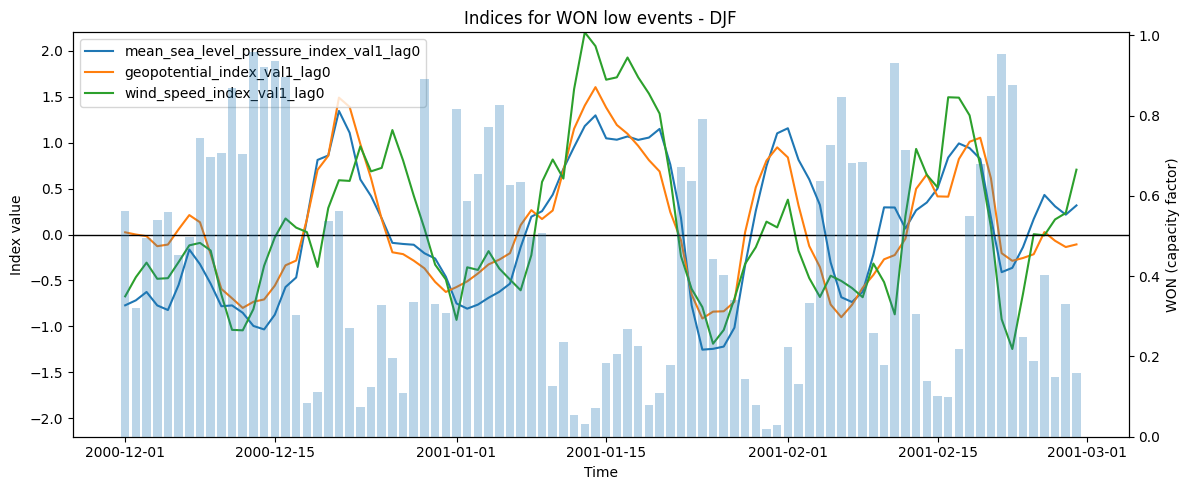

In [ ]:
start = "2000-12-01"
end   = "2001-02-28"

indices_plot = indices.sel(time=slice(start, end))
event_abs_plot = event_abs.sel(time=slice(start, end))

fig, ax1 = plt.subplots(figsize=(12, 5))

# -------------------
# LINIENPLOT (Indices, linke Achse)
# -------------------
# globale symmetrische Skala für alle Indices
data = indices_plot.to_array()

vmin = data.min().compute()
vmax = data.max().compute()

vabs = max(abs(vmin), abs(vmax))

for var in indices_plot.data_vars:
    ax1.plot(
        indices_plot["time"],
        indices_plot[var],
        label=var
    )

ax1.axhline(0, color="black", linewidth=1)
ax1.set_ylim(-vabs, vabs)
ax1.set_ylabel("Index value")
ax1.legend(loc="upper left")

# -------------------
# BALKENDIAGRAMM (event_abs, rechte Achse)
# -------------------
ax2 = ax1.twinx()

ax2.bar(
    event_abs_plot["time"].values,
    event_abs_plot.values,
    alpha=0.3
)

ax2.set_ylabel("WON (capacity factor)")

# -------------------
# Layout
# -------------------
ax1.set_xlabel("Time")
if extreme_event == "h":
    extreme_event_str = "high"
else:    extreme_event_str = "low"
plt.title(f"Indices for WON {extreme_event_str} events - DJF")
plt.tight_layout()
plt.savefig(f"fig/index_computation/{energy_entry.name}/{extreme_event}/indices_{energy_entry.name}_{extreme_event}_{start}_{end}.png", dpi=300)
plt.show()

## Multi Index Generator

In [ ]:
# kombiniere die drei bestimmten indices mittels gewichtung
def combine_indices(indices, weights, dim="time"):
    """
    indices: xr.Dataset mit mehreren Indices
    weights: dict, z.B. {"idx1": 1.0, "idx2": 0.5}
    """

    combined = None

    for var in indices.data_vars:
        w = weights.get(var, 1.0)
        data = indices[var] * w
        # print(w)

        combined = data if combined is None else combined + data

    # Standardisierung 
    combined = (combined - combined.mean(dim)) / combined.std(dim)

    return combined

In [ ]:
weight_sets = [
    {"mean_sea_level_pressure_index_val1_lag0": 1.0, "geopotential_index_val1_lag0": 1.0, "wind_speed_index_val1_lag0": 1.0},
    {"mean_sea_level_pressure_index_val1_lag0": 1.0, "geopotential_index_val1_lag0": 0.0, "wind_speed_index_val1_lag0": 1.0},
    {"mean_sea_level_pressure_index_val1_lag0": 1.0, "geopotential_index_val1_lag0": 1.0, "wind_speed_index_val1_lag0": 0.0},
    {"mean_sea_level_pressure_index_val1_lag0": 1.0, "geopotential_index_val1_lag0": 0.0, "wind_speed_index_val1_lag0": 0.7},
]

In [ ]:
combined_indices = []

for i, w in enumerate(weight_sets):
    ci = combine_indices(indices, w)
    ci.name = f"combo_{i}"
    combined_indices.append(ci)

combined_ds = xr.merge(combined_indices)

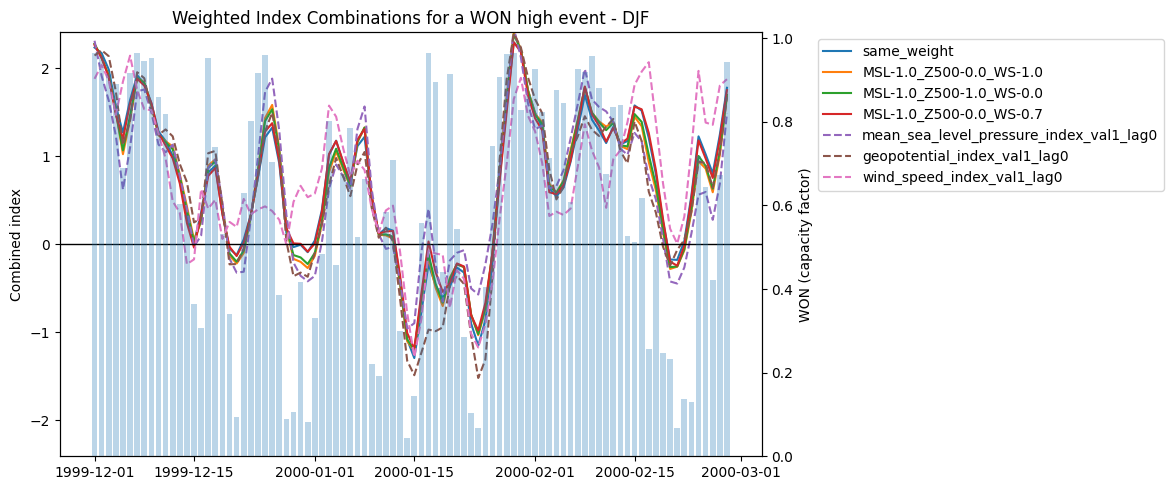

In [ ]:
start = "1999-12-01"
end   = "2000-02-28"

indices_plot = combined_ds.sel(time=slice(start, end))
event_abs_plot = event_abs.sel(time=slice(start, end))
indices_single = indices.sel(time=slice(start, end))

label_map = {
    "combo_0": "same_weight",
    "combo_1": "MSL-1.0_Z500-0.0_WS-1.0",
    "combo_2": "MSL-1.0_Z500-1.0_WS-0.0",
    "combo_3": "MSL-1.0_Z500-0.0_WS-0.7",
}

fig, ax1 = plt.subplots(figsize=(12, 5))

# ---- Linien (links) ----
for var in indices_plot.data_vars:
    ax1.plot(indices_plot["time"], indices_plot[var], label=label_map.get(var, var))

for var in indices_single.data_vars:
    ax1.plot(indices_single["time"], indices_single[var], label=var, linestyle="--")

ax1.axhline(0, color="black", linewidth=1)
ax1.set_ylabel("Combined index")
ax1.legend(loc="upper left", bbox_to_anchor=(1.07, 1))

# symmetrische Skala
vabs = float(max(
    abs(indices_plot.to_array().min().compute()),
    abs(indices_plot.to_array().max().compute())
))
ax1.set_ylim(-vabs, vabs)

# ---- Balken (rechts) ----
ax2 = ax1.twinx()

ax2.bar(
    event_abs_plot["time"].values,
    event_abs_plot.values,
    alpha=0.3
)

ax2.set_ylabel("WON (capacity factor)")

plt.title("Weighted Index Combinations for a WON high event - DJF")
plt.tight_layout()
plt.savefig(f"fig/index_computation/{energy_entry.name}/combined_indices_{energy_entry.name}_{extreme_event}_{start}_{end}_v2.png", dpi=300)
plt.show()

## Berechne Indices für verschiedene time lags 

In [ ]:
composites_lags = mask1_composite.sel(lag=[-4,-3,-2,-1,0])

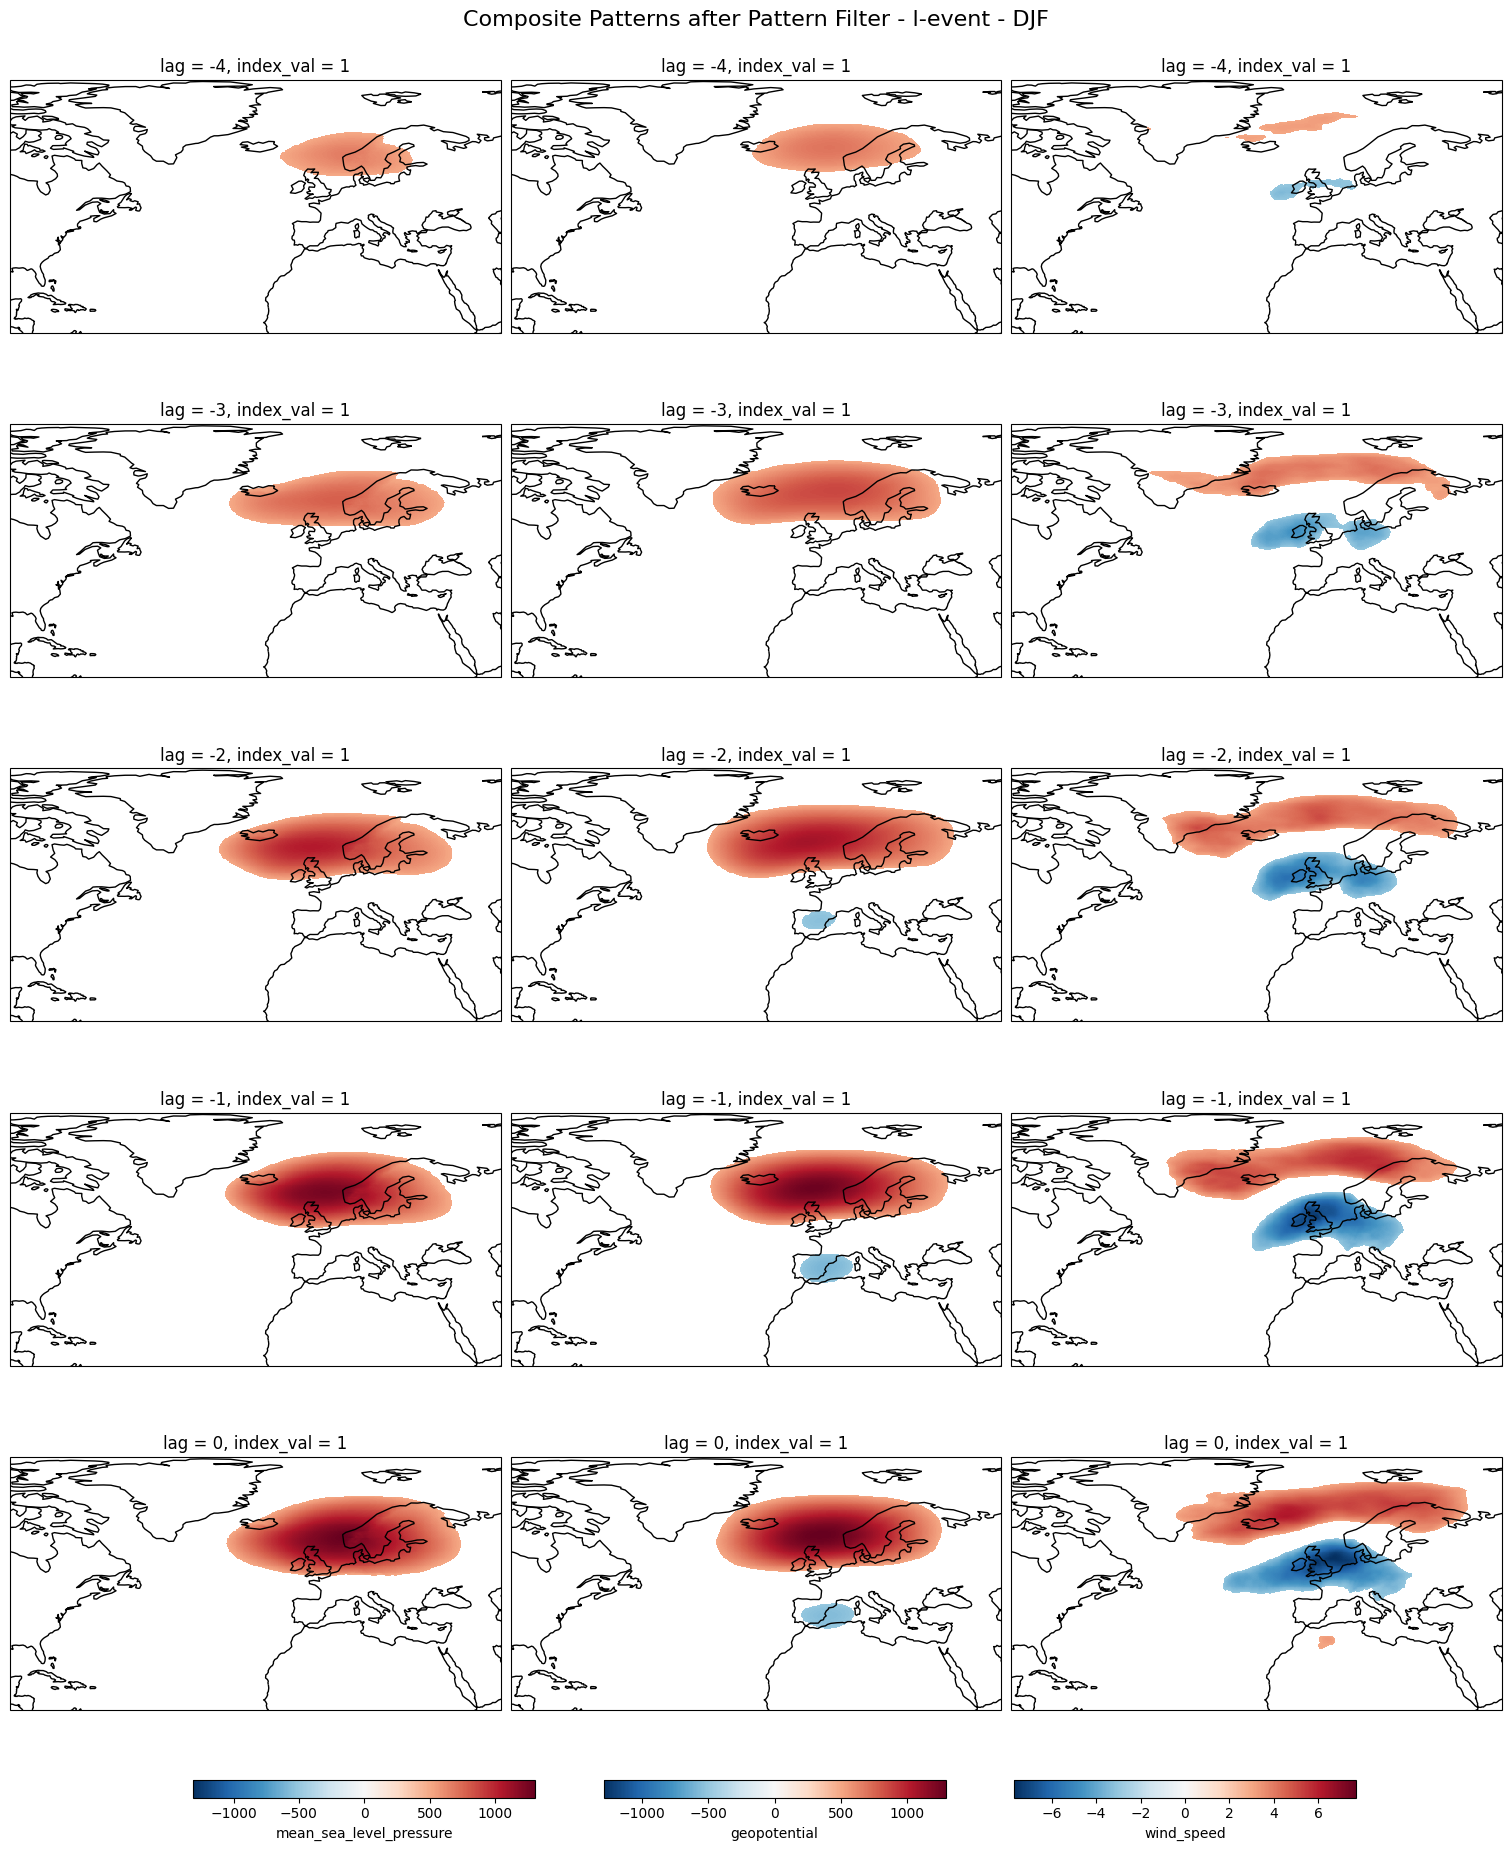

In [ ]:
lags = composites_lags.lag.values
vars = list(composites_lags.data_vars)

fig, axes = plt.subplots(
    len(lags), len(vars),
    figsize=(5 * len(vars), 3.5 * len(lags)),
    subplot_kw=dict(projection=ccrs.PlateCarree()),
    constrained_layout=True
)

# Achsen-Handling
if len(lags) == 1:
    axes = [axes]
if len(vars) == 1:
    axes = [[ax] for ax in axes]

# --- globale Farbskalen ---
vabs_dict = {}
for var in vars:
    data_all = composites_lags[var].sel(index_val=1)
    vabs = max(abs(data_all.min().item()), abs(data_all.max().item()))
    vabs_dict[var] = vabs

mappables = {}

# --- plotting ---
for i, lag in enumerate(lags):
    composite_pattern = composites_lags.sel(index_val=1, lag=lag)
    
    for j, var in enumerate(vars):
        ax = axes[i][j]
        data = composite_pattern[var]
        vabs = vabs_dict[var]

        im = data.plot(
            ax=ax,
            transform=ccrs.PlateCarree(),
            vmin=-vabs,
            vmax=vabs,
            cmap="RdBu_r",
            add_colorbar=False
        )

        if var not in mappables:
            mappables[var] = im

        ax.coastlines()
        
        # if j == 0:
        #     ax.text(
        #         0, 1.05, f"Lag {lag}",
        #         transform=ax.transAxes,
        #         fontsize=13,
        #         ha='left',
        #         va='bottom'
        #     )

# --- Layout: mehr Platz unten schaffen ---
plt.subplots_adjust(hspace=0.15, wspace=0.1, bottom=0.1)

# --- Colorbars explizit unter jede Spalte setzen ---
for j, var in enumerate(vars):
    # Position der untersten Achse der Spalte
    pos = axes[-1][j].get_position()
    
    # neue Achse darunter
    cax = fig.add_axes([
        pos.x0,          # gleiche x-Startposition
        pos.y0 - 0.15,   # etwas unterhalb
        pos.width,       # gleiche Breite
        0.01             # Höhe der Colorbar
    ])
    
    cbar = fig.colorbar(
        mappables[var],
        cax=cax,
        orientation='horizontal'
    )
    cbar.set_label(var)

# plt.suptitle(f"Composite Patterns - {extreme_event}-event - DJF", fontsize=16)
plt.suptitle(f"Composite Patterns after Pattern Filter - {extreme_event}-event - DJF", fontsize=16)
plt.subplots_adjust(top=0.5)

In [ ]:
# masken pattern filter erstellen
S=analyser.bootstrap_significance(2,p=0.1)
masked_composite=composites_lags.where(S==1)

In [ ]:
PF = PatternFilter(analyser=analyser)

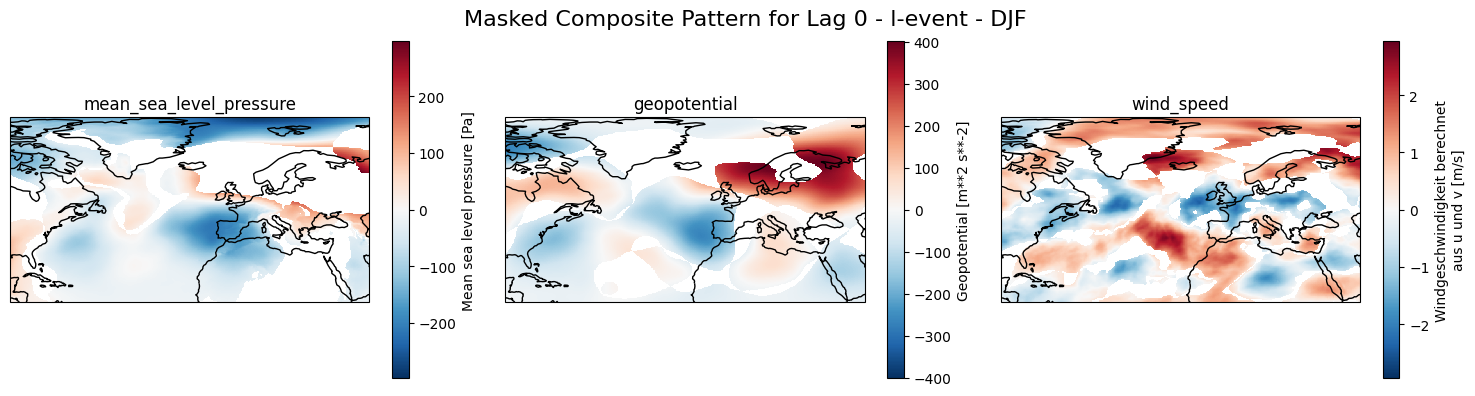

In [ ]:
composite_pattern=masked_composite.sel(index_val=1,lag=-7)
vars = list(composite_pattern.data_vars)
fig, axes = plt.subplots(
    1, len(vars),
    figsize=(5 * len(vars), 4),
    subplot_kw=dict(projection=ccrs.PlateCarree())
)

for ax, var in zip(axes, vars):
    data = composite_pattern[var]
    vabs = max(abs(data.min().item()), abs(data.max().item()))
    data.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        vmin=-vabs,
        vmax=vabs,
        cmap="RdBu_r",
        add_colorbar=True
    )
    ax.coastlines()
    ax.set_title(var)

plt.suptitle(f"Masked Composite Pattern for Lag 0 - {extreme_event}-event - DJF", fontsize=16)
plt.tight_layout()
plt.subplots_adjust(top=0.9)

**Suche lag aus und erstelle dafür einen Index**

In [ ]:
lag_id = -1

In [ ]:
thresh_dict=dict(mean_sea_level_pressure=500,geopotential=500,wind_speed=5.)

def abs_amplitude_over_threshold(val_ds,thresh_dict):
    return abs(val_ds)>xr.Dataset(thresh_dict)

PF.apply_value_mask(abs_amplitude_over_threshold,thresh_dict,mode='intersection')
mask_lags=PF.get_mask() #retrieve the new mask for plotting later.

In [ ]:
lags

array([-9, -8, -7, -6, -5, -4, -3, -2, -1,  0])

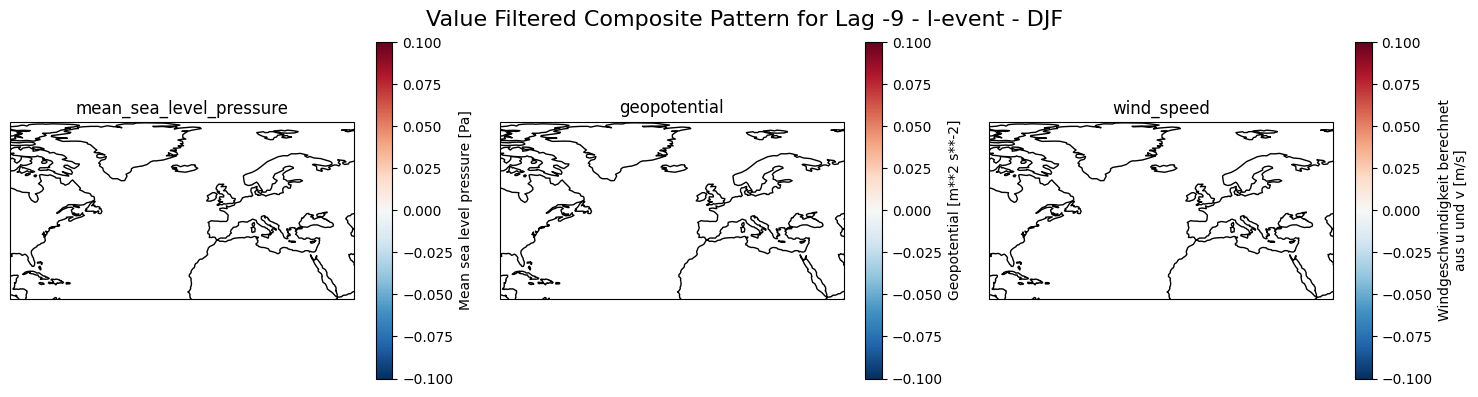

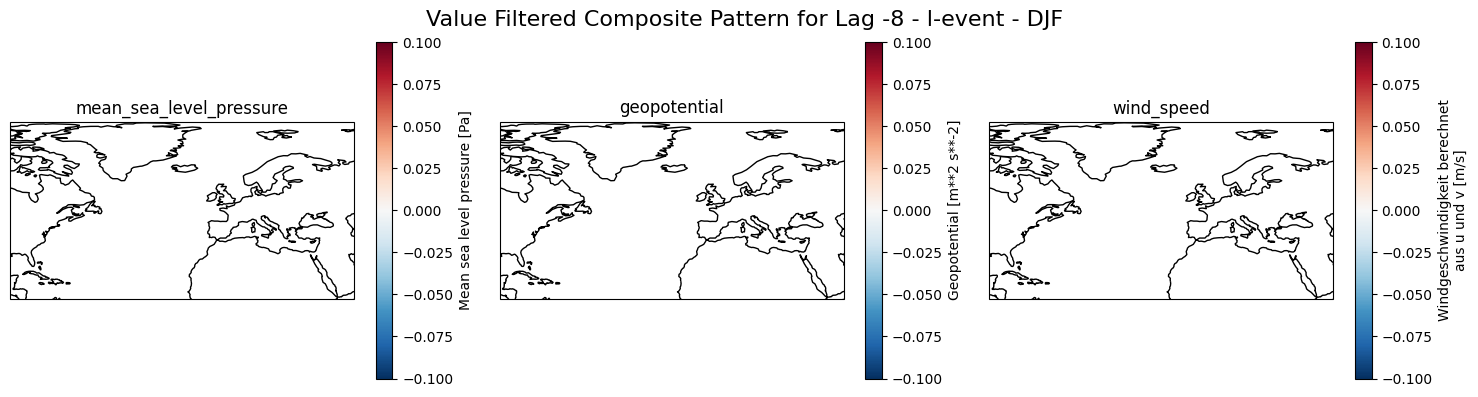

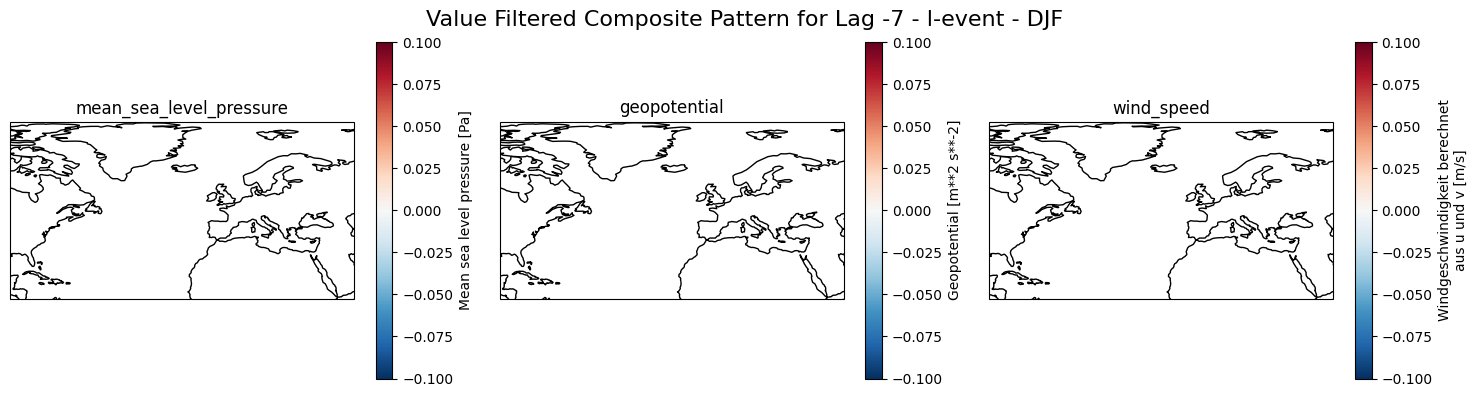

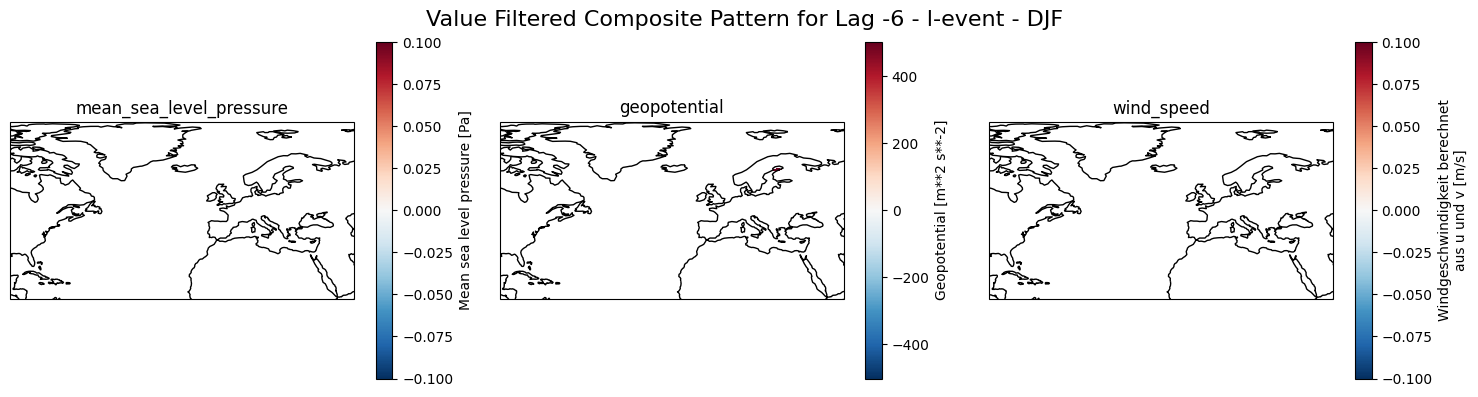

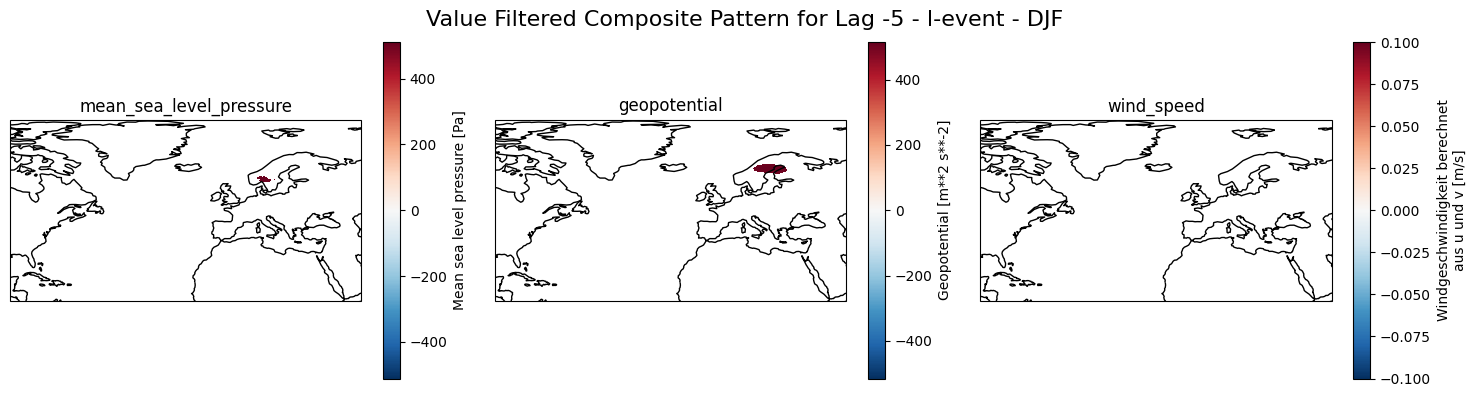

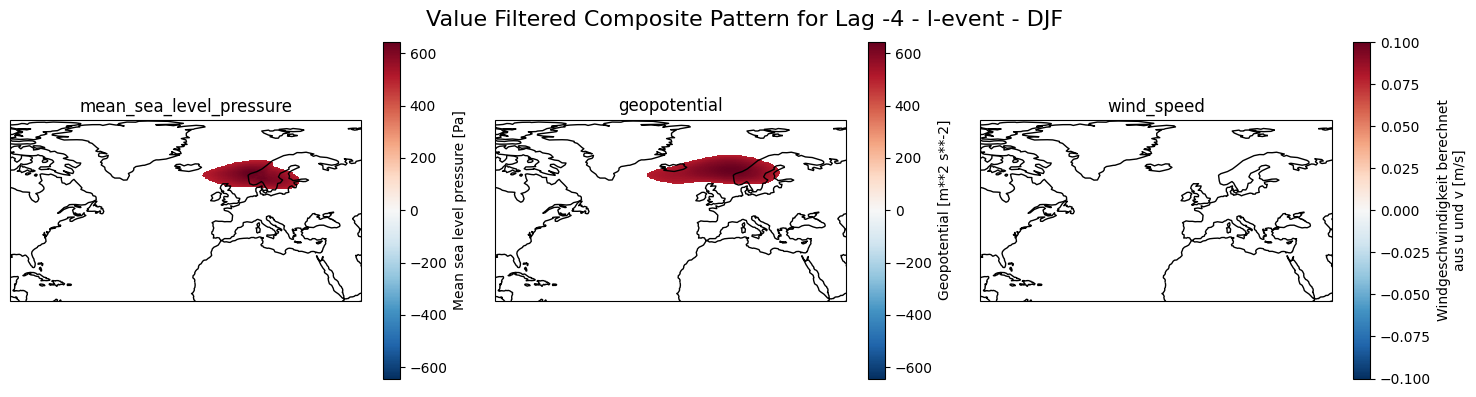

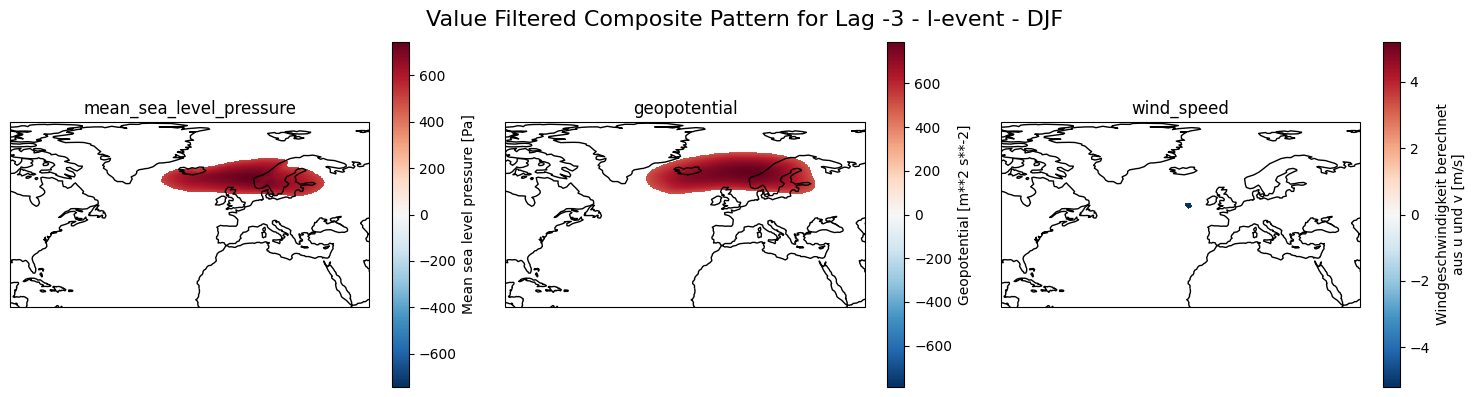

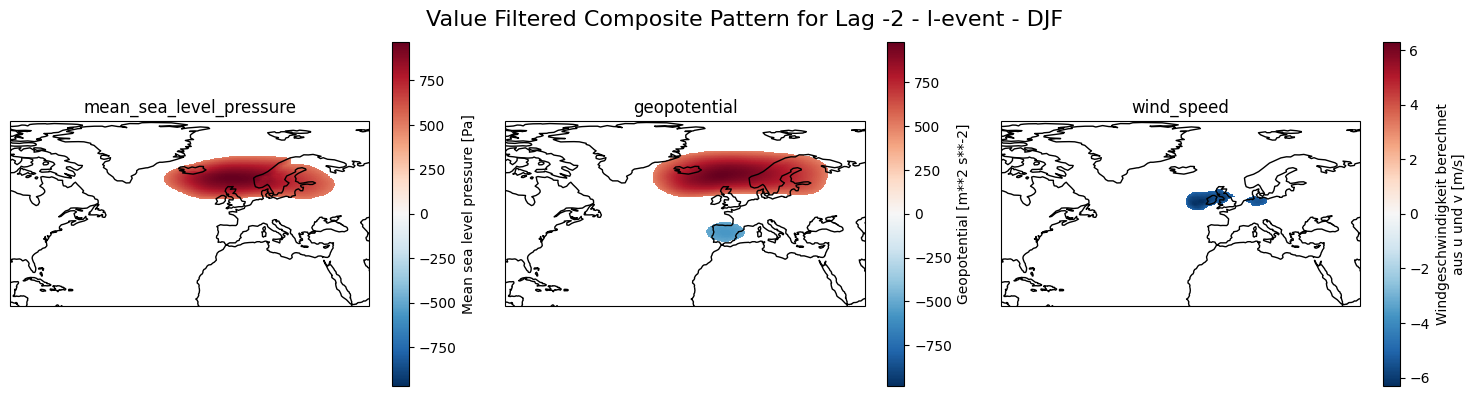

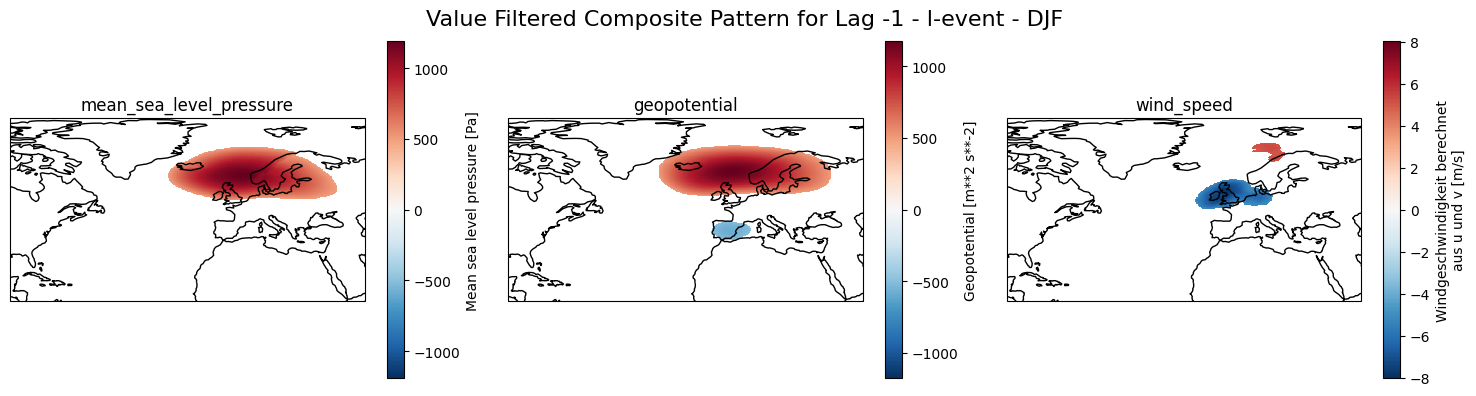

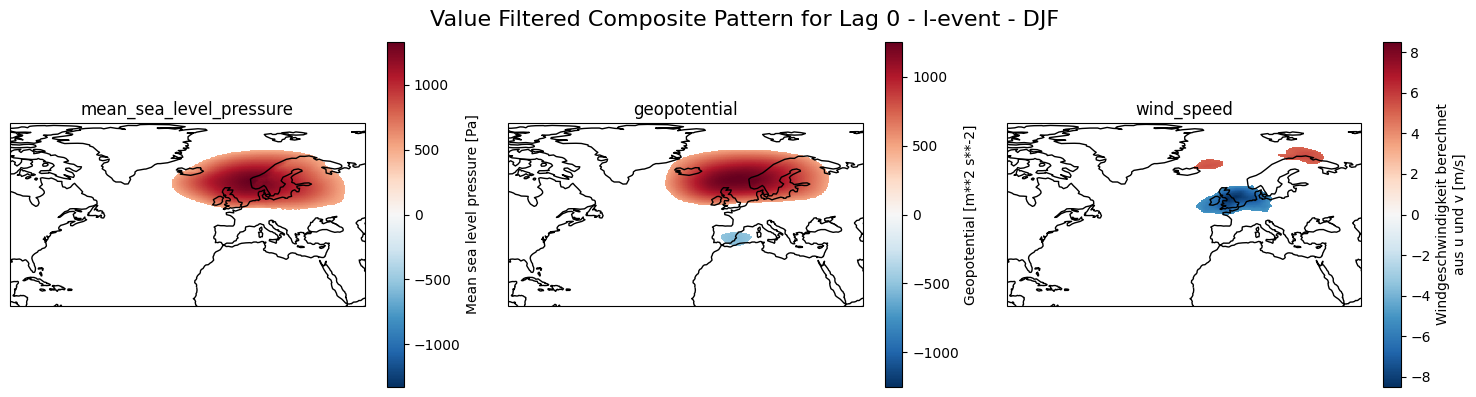

In [ ]:

for lag_id in lags:
    mask1_composite=masked_composite.where(mask_lags==1)
    composite_pattern=mask1_composite.sel(index_val=1,lag=lag_id)
    vars = list(composite_pattern.data_vars)
    fig, axes = plt.subplots(
        1, len(vars),
        figsize=(5 * len(vars), 4),
        subplot_kw=dict(projection=ccrs.PlateCarree())
    )

    for ax, var in zip(axes, vars):
        data = composite_pattern[var]
        vabs = max(abs(data.min().item()), abs(data.max().item()))
        data.plot(
            ax=ax,
            transform=ccrs.PlateCarree(),
            vmin=-vabs,
            vmax=vabs,
            cmap="RdBu_r",
            add_colorbar=True
        )
        ax.coastlines()
        ax.set_title(var)

    plt.suptitle(f"Value Filtered Composite Pattern for Lag {lag_id} - {extreme_event}-event - DJF", fontsize=16)
    plt.tight_layout()
    plt.subplots_adjust(top=0.9)

## Neuer Index Generator für alle lags

In [ ]:
IG=IndexGenerator()

In [ ]:
# DJF_variables=xr.align(analyser.variables,analyser.event)[0]

In [ ]:
# index_slices = [
#     {'index_val': 1, 'lag': -2},
#     {'index_val': 1, 'lag': -3},
#     {'index_val': 1, 'lag': -4},
#     # {'index_val': 1, 'lag': -5},
#     # {'index_val': 1, 'lag': -6},
#     # {'index_val': 1, 'lag': -7},
#     # {'index_val': 1, 'lag': -8},
#     # {'index_val': 1, 'lag': -9},
#     {'index_val': 1, 'lag': 0},
#     {'index_val': 1, 'lag': -1}
# ]

In [ ]:
# SON_variables_chunks

<xarray.Dataset> Size: 5GB
Dimensions:                  (time: 2798, latitude: 289, longitude: 561)
Coordinates:
  * time                     (time) datetime64[us] 22kB 1980-01-01 ... 2010-1...
    dayofyear                (time) int64 22kB dask.array<chunksize=(100,), meta=np.ndarray>
    level                    (time) int64 22kB dask.array<chunksize=(100,), meta=np.ndarray>
  * latitude                 (latitude) float32 1kB 84.0 83.75 ... 12.25 12.0
  * longitude                (longitude) float32 2kB -90.0 -89.75 ... 49.75 50.0
Data variables:
    mean_sea_level_pressure  (time, latitude, longitude) float32 2GB dask.array<chunksize=(100, 289, 561), meta=np.ndarray>
    geopotential             (time, latitude, longitude) float32 2GB dask.array<chunksize=(100, 289, 561), meta=np.ndarray>
    wind_speed               (time, latitude, longitude) float32 2GB dask.array<chunksize=(100, 289, 561), meta=np.ndarray>

In [ ]:
# # masked_composite_chunks = masked_composite.chunk({'time': 100})
# DJF_variables_chunks = DJF_variables.chunk({'time': 50})
# indices=IG.generate(composites_lags,DJF_variables_chunks,dim='time',slices=index_slices)

In [ ]:
# lags_plot = [-4,-3,-2,-1,0]

Data variables:
    mean_sea_level_pressure_index_val1_lag-4  (time) float32 11kB dask.array<chunksize=(100,), meta=np.ndarray>
    geopotential_index_val1_lag-4             (time) float32 11kB dask.array<chunksize=(100,), meta=np.ndarray>
    wind_speed_index_val1_lag-4               (time) float32 11kB dask.array<chunksize=(100,), meta=np.ndarray>


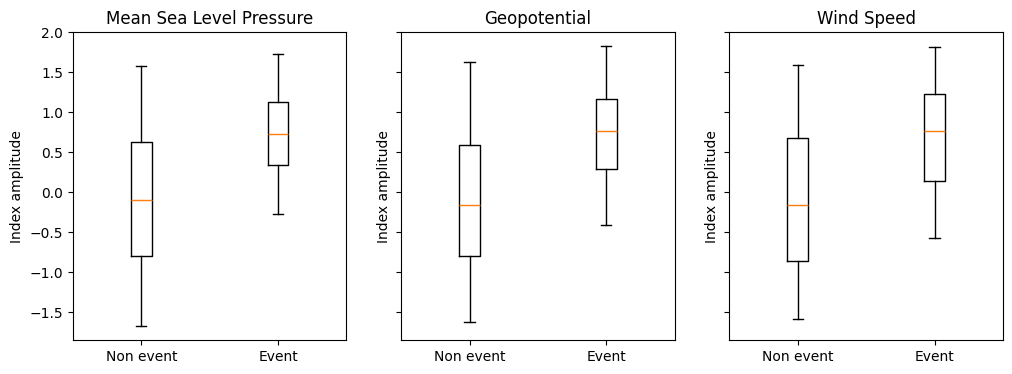

Data variables:
    mean_sea_level_pressure_index_val1_lag-3  (time) float32 11kB dask.array<chunksize=(100,), meta=np.ndarray>
    geopotential_index_val1_lag-3             (time) float32 11kB dask.array<chunksize=(100,), meta=np.ndarray>
    wind_speed_index_val1_lag-3               (time) float32 11kB dask.array<chunksize=(100,), meta=np.ndarray>


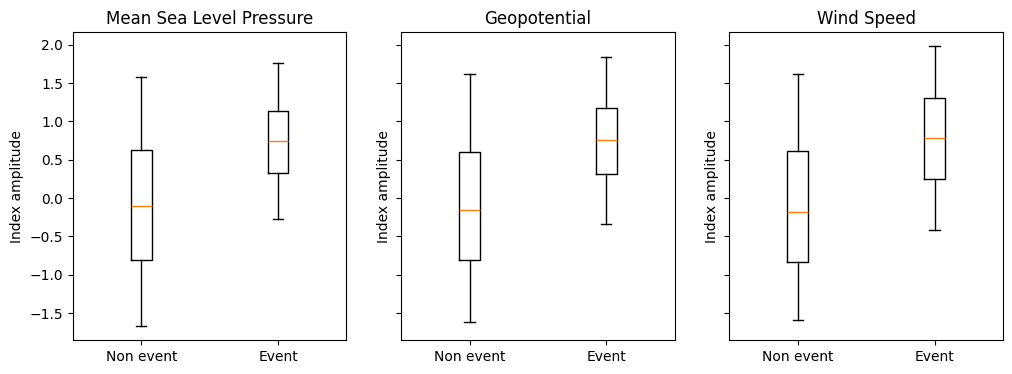

Data variables:
    mean_sea_level_pressure_index_val1_lag-2  (time) float32 11kB dask.array<chunksize=(100,), meta=np.ndarray>
    geopotential_index_val1_lag-2             (time) float32 11kB dask.array<chunksize=(100,), meta=np.ndarray>
    wind_speed_index_val1_lag-2               (time) float32 11kB dask.array<chunksize=(100,), meta=np.ndarray>


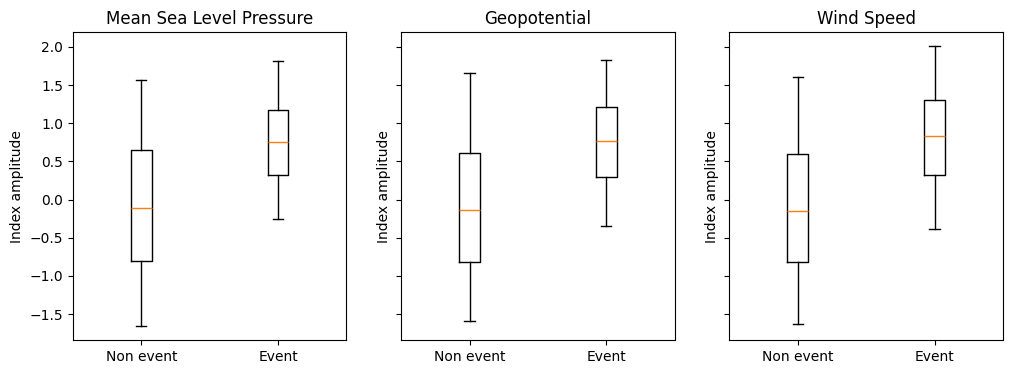

Data variables:
    mean_sea_level_pressure_index_val1_lag-1  (time) float32 11kB dask.array<chunksize=(100,), meta=np.ndarray>
    geopotential_index_val1_lag-1             (time) float32 11kB dask.array<chunksize=(100,), meta=np.ndarray>
    wind_speed_index_val1_lag-1               (time) float32 11kB dask.array<chunksize=(100,), meta=np.ndarray>


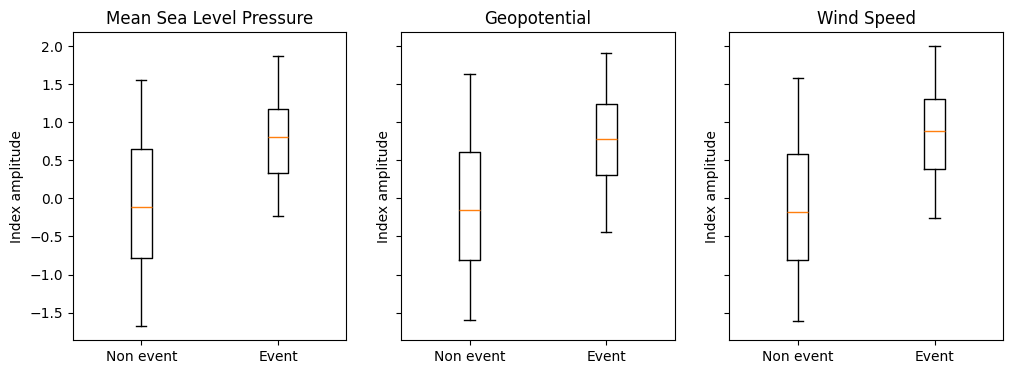

Data variables:
    mean_sea_level_pressure_index_val1_lag0  (time) float32 11kB dask.array<chunksize=(100,), meta=np.ndarray>
    geopotential_index_val1_lag0             (time) float32 11kB dask.array<chunksize=(100,), meta=np.ndarray>
    wind_speed_index_val1_lag0               (time) float32 11kB dask.array<chunksize=(100,), meta=np.ndarray>


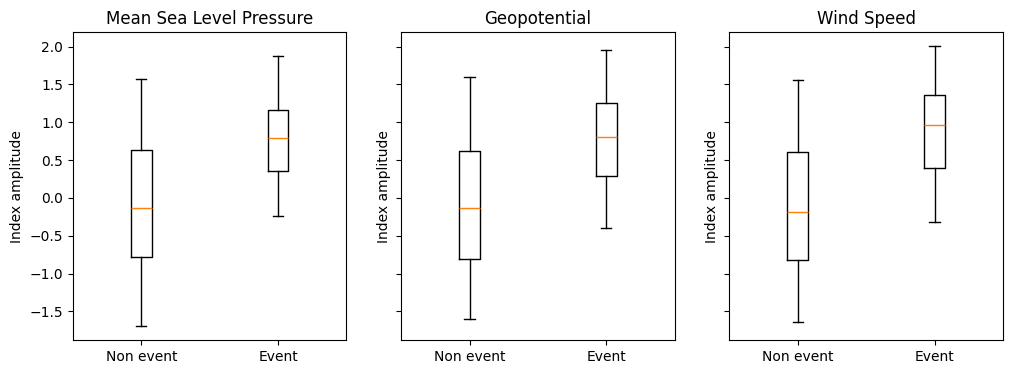

In [ ]:
# event_training = event.sel(time=slice('1980','2010'))
# for lag_id in lags_plot:

#     # berechne die indices für alle zeitpunkte und teile sie in event vs non-event auf
#     index_slices=[dict(index_val=1,lag=lag_id)]
#     indices=IG.generate(masked_composite,SON_variables_chunks,dim='time',slices=index_slices)
#     print(indices.data_vars)

#     fig,ax=plt.subplots(1,3, figsize=(12,4), sharey=True)

#     ax[0].boxplot(indices[f'mean_sea_level_pressure_index_val1_lag{lag_id}'][event_training==0].values,whis=[5,95],positions=[0],showfliers=False)
#     ax[0].boxplot(indices[f'mean_sea_level_pressure_index_val1_lag{lag_id}'][event_training==1].values,whis=[5,95],positions=[1],showfliers=False)
#     ax[0].set_title('Mean Sea Level Pressure')

#     ax[1].boxplot(indices[f'geopotential_index_val1_lag{lag_id}'][event_training==0].values,whis=[5,95],positions=[0],showfliers=False)
#     ax[1].boxplot(indices[f'geopotential_index_val1_lag{lag_id}'][event_training==1].values,whis=[5,95],positions=[1],showfliers=False)
#     ax[1].set_title('Geopotential')

#     ax[2].boxplot(indices[f'wind_speed_index_val1_lag{lag_id}'][event_training==0].values,whis=[5,95],positions=[0],showfliers=False)
#     ax[2].boxplot(indices[f'wind_speed_index_val1_lag{lag_id}'][event_training==1].values,whis=[5,95],positions=[1],showfliers=False)
#     ax[2].set_title('Wind Speed')

#     for a in ax:
#         a.set_ylabel('Index amplitude')
#         a.set_xticklabels(['Non event', 'Event'])


#     plt.savefig(f"fig/index_computation/{energy_entry.name}/{extreme_event}/boxplot_indices_{energy_entry.name}_{extreme_event}_lag{lag_id}_training.png", dpi=300)
#     plt.show()

## Plots für alle Indices verschiedene lags

In [ ]:
indices.data_vars 

Data variables:
    mean_sea_level_pressure_index_val1_lag0  (time) float32 11kB dask.array<chunksize=(100,), meta=np.ndarray>
    geopotential_index_val1_lag0             (time) float32 11kB dask.array<chunksize=(100,), meta=np.ndarray>
    wind_speed_index_val1_lag0               (time) float32 11kB dask.array<chunksize=(100,), meta=np.ndarray>

In [ ]:
# funktioniert nur wenn durchgelaufen für alle lags und indices in einem. crasht bei neuer aufteilung von trainingsset.

Plotting lag -4...


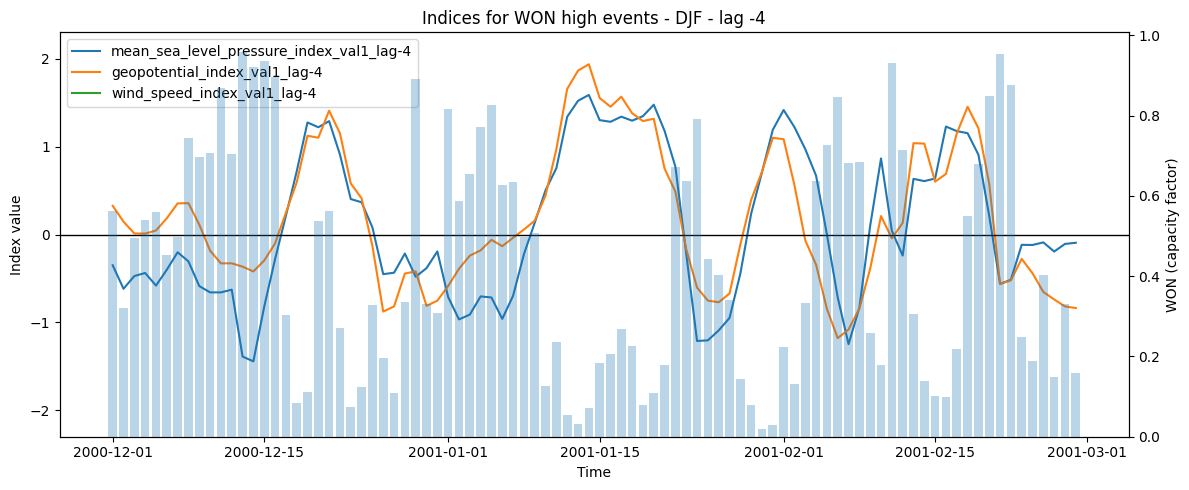

Plotting lag -3...


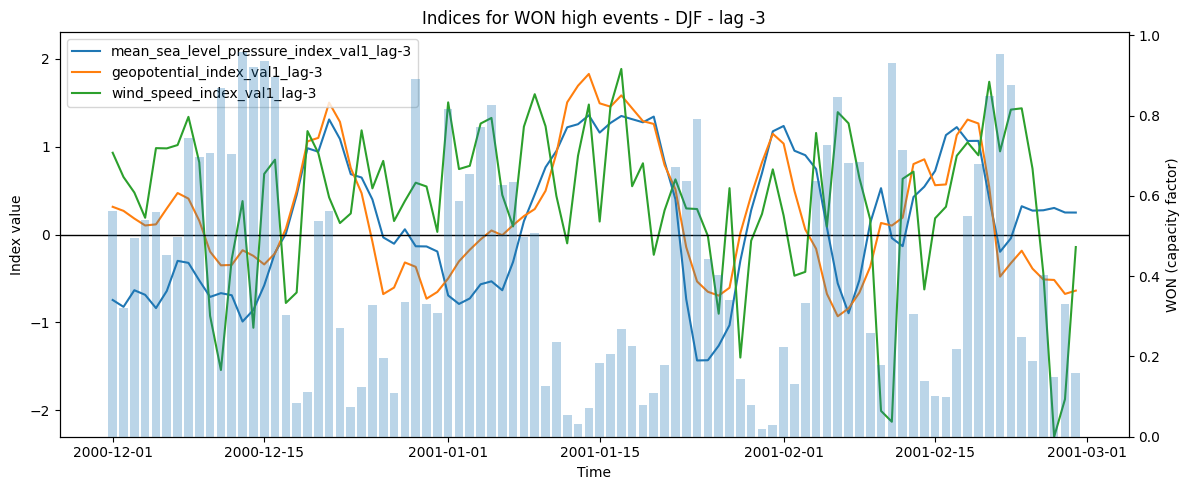

Plotting lag -2...


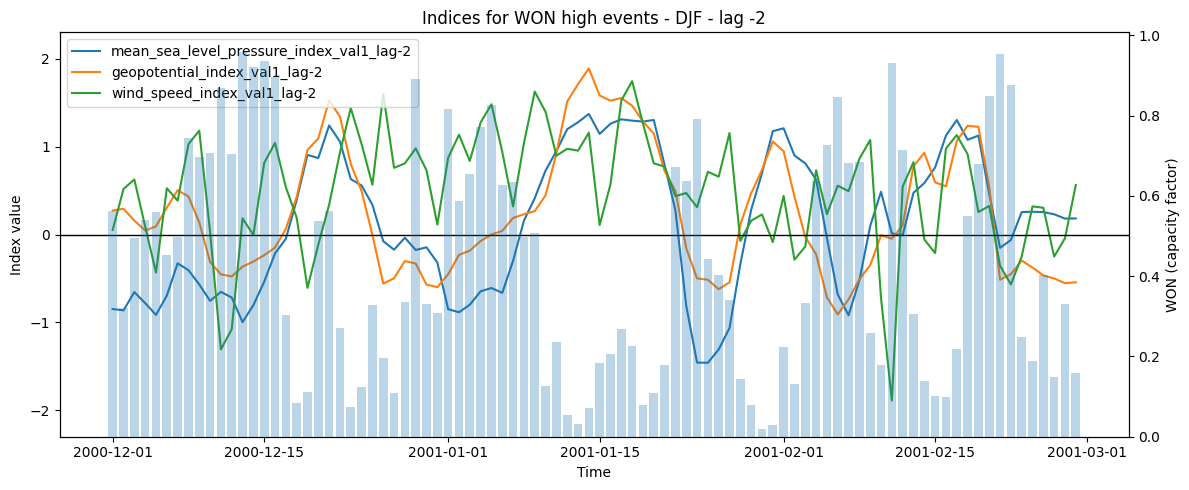

Plotting lag -1...


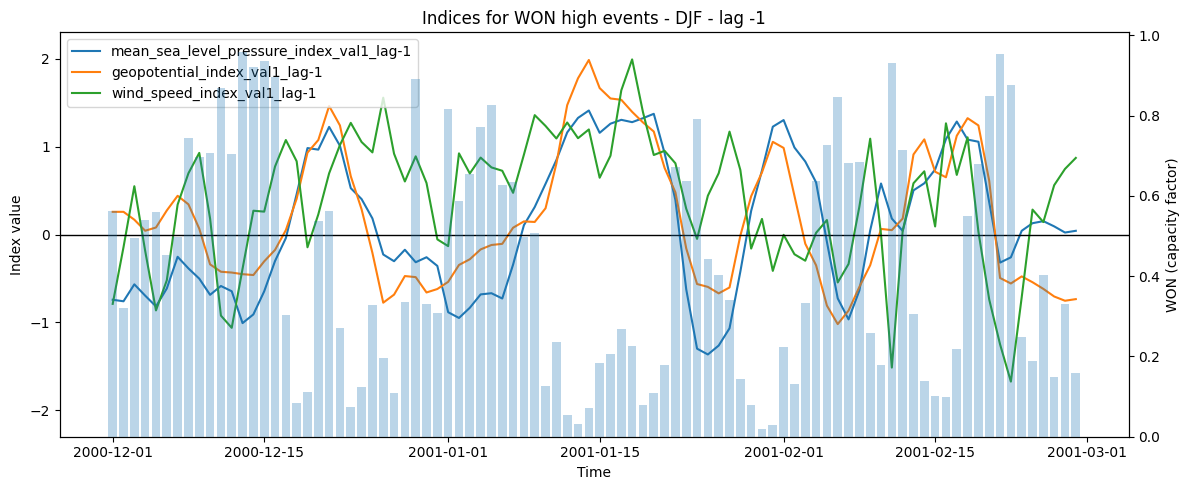

Plotting lag 0...


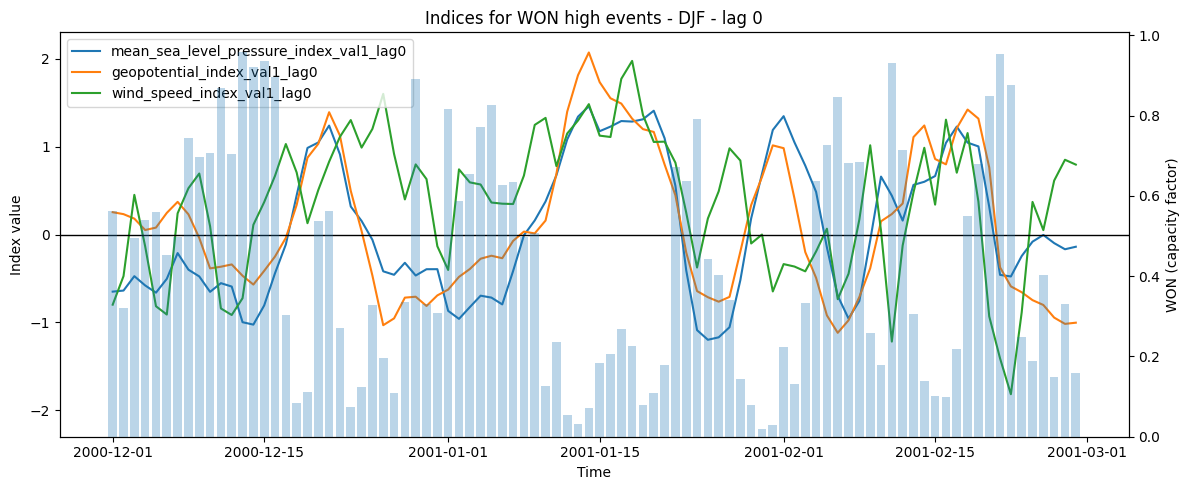

In [ ]:
start = "2000-12-01"
end   = "2001-02-28"

indices_plot = indices.sel(time=slice(start, end))
event_abs_plot = event_abs.sel(time=slice(start, end))

for lag in lags_plot:
    lag_id = lag
    print(f"Plotting lag {lag_id}...")
    selected_vars = [f'mean_sea_level_pressure_index_val1_lag{lag_id}',f'geopotential_index_val1_lag{lag_id}',f'wind_speed_index_val1_lag{lag_id}']
    indices_plot_sel = indices_plot[selected_vars]

    fig, ax1 = plt.subplots(figsize=(12, 5))

    # -------------------
    # LINIENPLOT (Indices, linke Achse)
    # -------------------
    # globale symmetrische Skala für alle Indices
    data = indices_plot.to_array()

    vmin = data.min().compute()
    vmax = data.max().compute()

    vabs = max(abs(vmin), abs(vmax))

    for var in indices_plot_sel.data_vars:
        ax1.plot(
            indices_plot_sel["time"],
            indices_plot_sel[var],
            label=var
        )

    ax1.axhline(0, color="black", linewidth=1)
    ax1.set_ylim(-vabs, vabs)
    ax1.set_ylabel("Index value")
    ax1.legend(loc="upper left")

    # -------------------
    # BALKENDIAGRAMM (event_abs, rechte Achse)
    # -------------------
    ax2 = ax1.twinx()

    ax2.bar(
        event_abs_plot["time"].values,
        event_abs_plot.values,
        alpha=0.3
    )

    ax2.set_ylabel("WON (capacity factor)")

    # -------------------
    # Layout
    # -------------------
    ax1.set_xlabel("Time")
    plt.title(f"Indices for WON high events - DJF - lag {lag_id}")
    plt.tight_layout()
    plt.savefig(f"fig/index_computation/{energy_entry.name}/indices_{energy_entry.name}_{extreme_event}_{start}_{end}_lag{lag_id}.png", dpi=300)
    plt.show()
    plt.close()

Plotting variable mean_sea_level_pressure for all lags...


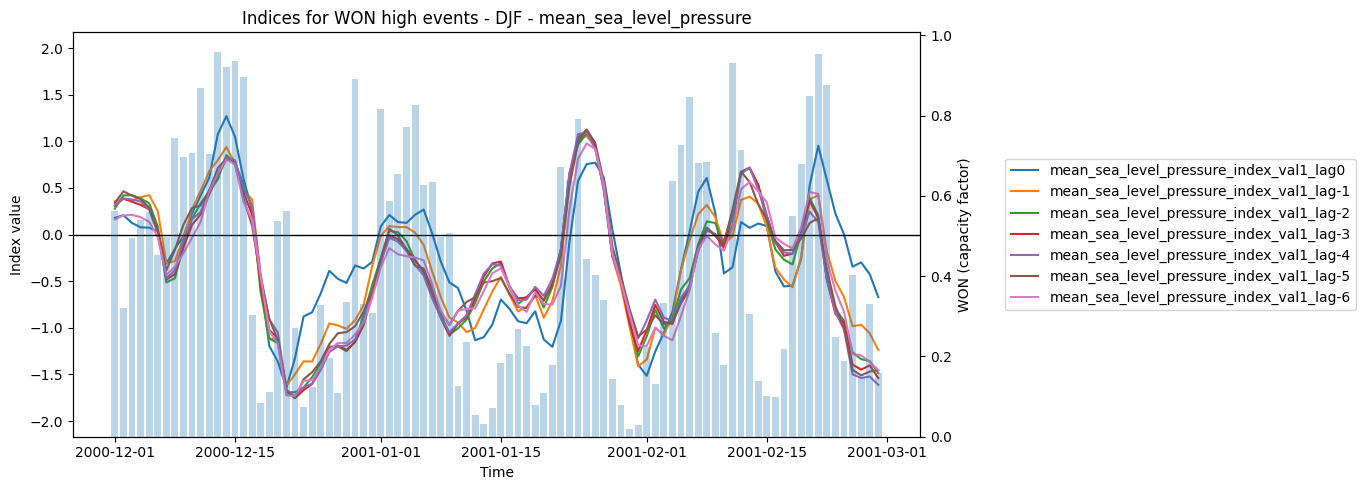

Plotting variable geopotential for all lags...


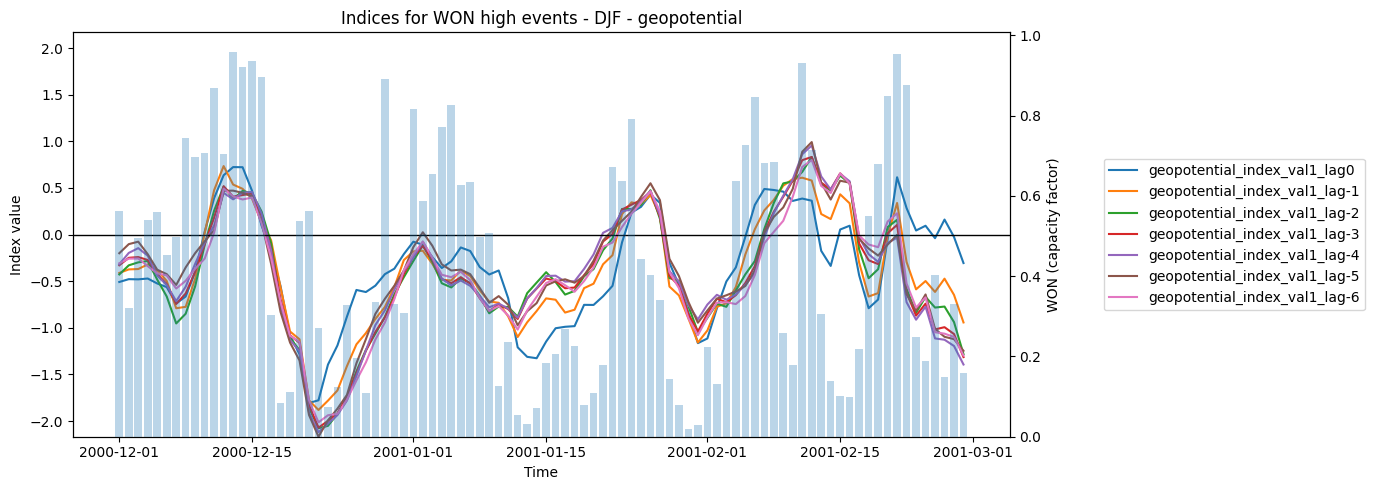

Plotting variable wind_speed for all lags...


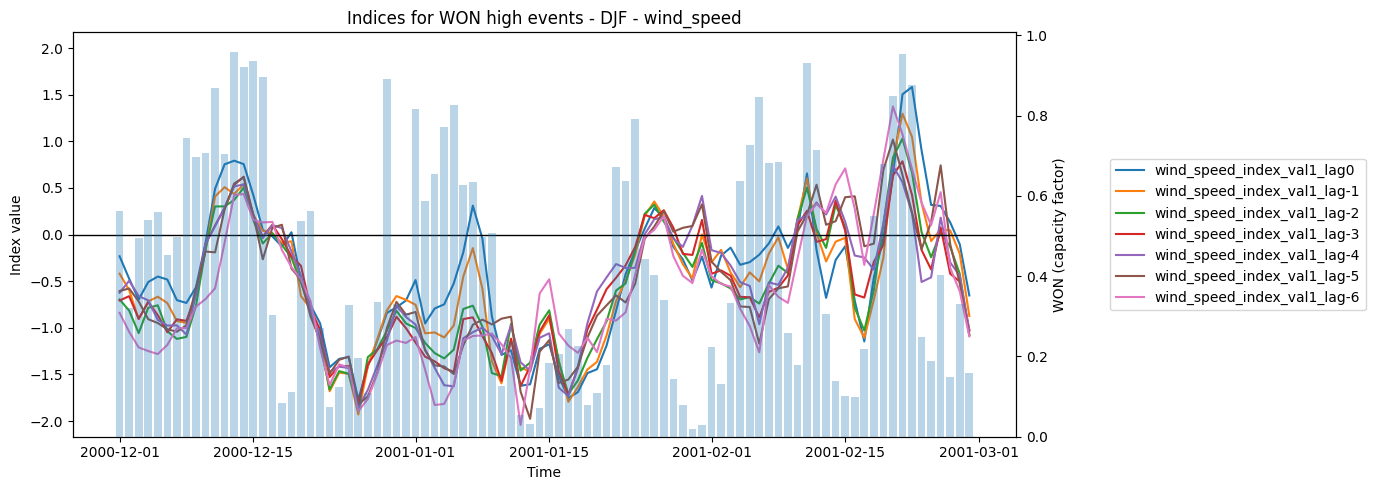

In [ ]:
start = "2000-12-01"
end   = "2001-02-28"

indices_plot = indices.sel(time=slice(start, end))
event_abs_plot = event_abs.sel(time=slice(start, end))
variables = ['mean_sea_level_pressure', 'geopotential', 'wind_speed']
for vari in variables:
    print(f"Plotting variable {vari} for all lags...")
    selected_vars = [f'{vari}_index_val1_lag0',f'{vari}_index_val1_lag-1',f'{vari}_index_val1_lag-2',f'{vari}_index_val1_lag-3',f'{vari}_index_val1_lag-4',f'{vari}_index_val1_lag-5',f'{vari}_index_val1_lag-6']
    indices_plot_sel = indices_plot[selected_vars]

    fig, ax1 = plt.subplots(figsize=(14, 5))

    # -------------------
    # LINIENPLOT (Indices, linke Achse)
    # -------------------
    # globale symmetrische Skala für alle Indices
    data = indices_plot.to_array()

    vmin = data.min().compute()
    vmax = data.max().compute()

    vabs = max(abs(vmin), abs(vmax))

    for var in indices_plot_sel.data_vars:
        ax1.plot(
            indices_plot_sel["time"],
            indices_plot_sel[var],
            label=var
        )

    ax1.axhline(0, color="black", linewidth=1)
    ax1.set_ylim(-vabs, vabs)
    ax1.set_ylabel("Index value")
    ax1.legend(
        loc="center left",
        bbox_to_anchor=(1.1, 0.5),
        borderaxespad=0
    )

    # -------------------
    # BALKENDIAGRAMM (event_abs, rechte Achse)
    # -------------------
    ax2 = ax1.twinx()

    ax2.bar(
        event_abs_plot["time"].values,
        event_abs_plot.values,
        alpha=0.3
    )

    ax2.set_ylabel("WON (capacity factor)")

    # -------------------
    # Layout
    # -------------------
    ax1.set_xlabel("Time")
    plt.title(f"Indices for WON high events - DJF - {vari}")
    plt.tight_layout()
    plt.savefig(f"fig/index_computation/{energy_entry.name}/indices_{energy_entry.name}_{extreme_event}_{vari}_{start}_{end}.png", dpi=300)
    plt.show()
    plt.close()

## Prediction Test

In [ ]:
standardisation_params=IG.get_standardisation_params()
ixmean=standardisation_params.sel(param='mean')
ixstd=standardisation_params.sel(param='std')
test_predictor_chunks = test_predictor.chunk({'time': 100})
test_index=IG.generate(masked_composite,test_predictor_chunks,dim='time',slices=index_slices, ix_means=ixmean,ix_stds=ixstd)

In [ ]:
test_index

<xarray.Dataset> Size: 273kB
Dimensions:                                   (time: 1895)
Coordinates:
  * time                                      (time) datetime64[ns] 15kB 2002...
    dayofyear                                 (time) int64 15kB dask.array<chunksize=(100,), meta=np.ndarray>
    level                                     (time) int64 15kB dask.array<chunksize=(100,), meta=np.ndarray>
    lag                                       int64 8B -2
    index_val                                 int64 8B 1
Data variables: (12/15)
    mean_sea_level_pressure_index_val1_lag-2  (time) float64 15kB dask.array<chunksize=(100,), meta=np.ndarray>
    geopotential_index_val1_lag-2             (time) float64 15kB dask.array<chunksize=(100,), meta=np.ndarray>
    wind_speed_index_val1_lag-2               (time) float64 15kB dask.array<chunksize=(100,), meta=np.ndarray>
    mean_sea_level_pressure_index_val1_lag-3  (time) float64 15kB dask.array<chunksize=(100,), meta=np.ndarray>
    geopotential_index_val1_lag-3             (time) float64 15kB dask.array<chunksize=(100,), meta=np.ndarray>
    wind_speed_index_val1_lag-3               (time) float64 15kB dask.array<chunksize=(100,), meta=np.ndarray>
    ...                                        ...
    mean_sea_level_pressure_index_val1_lag0   (time) float64 15kB dask.array<chunksize=(100,), meta=np.ndarray>
    geopotential_index_val1_lag0              (time) float64 15kB dask.array<chunksize=(100,), meta=np.ndarray>
    wind_speed_index_val1_lag0                (time) float64 15kB dask.array<chunksize=(100,), meta=np.ndarray>
    mean_sea_level_pressure_index_val1_lag-1  (time) float64 15kB dask.array<chunksize=(100,), meta=np.ndarray>
    geopotential_index_val1_lag-1             (time) float64 15kB dask.array<chunksize=(100,), meta=np.ndarray>
    wind_speed_index_val1_lag-1               (time) float64 15kB dask.array<chunksize=(100,), meta=np.ndarray>

In [ ]:
test_index_v2=IG.generate(masked_composite,test_predictor, dim='time',slices=index_slices)

In [ ]:
test_index_v2

<xarray.DataArray (variable: 15, time: 1895)> Size: 114kB
array([[ 0.72997165,  0.8376526 ,  1.2058603 , ..., -1.1225222 ,
        -1.2439461 , -1.1529582 ],
       [ 0.10900408,  0.6126819 ,  1.2535672 , ..., -1.179375  ,
        -1.28328   , -1.3125317 ],
       [ 0.453892  ,  0.92407763,  1.322142  , ...,  0.2061286 ,
        -0.2589145 , -0.88393235],
       ...,
       [ 0.7665782 ,  0.88695437,  1.2534472 , ..., -1.2084466 ,
        -1.3736537 , -1.2745965 ],
       [ 0.08879278,  0.65244377,  1.336158  , ..., -1.3152986 ,
        -1.3805182 , -1.3357718 ],
       [ 0.21235043,  0.89416015,  1.4280615 , ...,  0.01585104,
        -0.2810651 , -1.120446  ]], shape=(15, 1895), dtype=float32)
Coordinates:
  * variable   (variable) object 120B 'mean_sea_level_pressure_index_val1_lag...
  * time       (time) datetime64[ns] 15kB 2002-01-01 2002-01-02 ... 2022-12-31
    dayofyear  (time) int64 15kB 1 2 3 4 5 6 7 8 ... 359 360 361 362 363 364 365
    level      (time) int64 15kB 500 500 500 500 500 500 ... 500 500 500 500 500
    lag        int64 8B -2
    index_val  int64 8B 1

In [ ]:
da = test_index.sel(variable="mean_sea_level_pressure_index_val1_lag0")
da2 = test_index_v2.sel(variable="mean_sea_level_pressure_index_val1_lag0")

Text(0, 0.5, 'Standardised with test index directly')

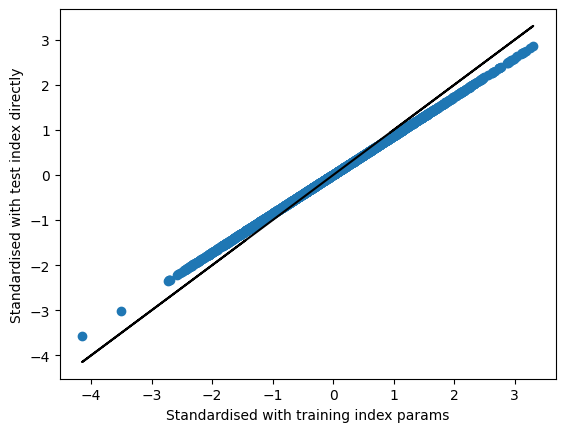

In [ ]:
da2_plot=da2#.to_array().squeeze()#test_index_v2['mean_sea_level_pressure_index_val1_lag-2'].to_array().squeeze()
da_plot=da#.to_array().squeeze()#test_index['mean_sea_level_pressure_index_val1_lag-2'].to_array().squeeze()
plt.scatter(da_plot,da2_plot)
plt.plot(da_plot,da_plot,color='k')
plt.gca().set_xlabel('Standardised with training index params')
plt.gca().set_ylabel('Standardised with test index directly')

In [ ]:
clean_vars = [
    var for var in indices.data_vars
    if not indices[var].isnull().any().compute()
]

ds_clean = indices[clean_vars]

In [ ]:
ds_clean

<xarray.Dataset> Size: 159kB
Dimensions:                                   (time: 1986)
Coordinates:
  * time                                      (time) datetime64[us] 16kB 1980...
    dayofyear                                 (time) int64 16kB dask.array<chunksize=(100,), meta=np.ndarray>
    level                                     (time) int64 16kB dask.array<chunksize=(100,), meta=np.ndarray>
    lag                                       int64 8B -2
    index_val                                 int64 8B 1
Data variables: (12/14)
    mean_sea_level_pressure_index_val1_lag-2  (time) float32 8kB dask.array<chunksize=(100,), meta=np.ndarray>
    geopotential_index_val1_lag-2             (time) float32 8kB dask.array<chunksize=(100,), meta=np.ndarray>
    wind_speed_index_val1_lag-2               (time) float32 8kB dask.array<chunksize=(100,), meta=np.ndarray>
    mean_sea_level_pressure_index_val1_lag-3  (time) float32 8kB dask.array<chunksize=(100,), meta=np.ndarray>
    geopotential_index_val1_lag-3             (time) float32 8kB dask.array<chunksize=(100,), meta=np.ndarray>
    wind_speed_index_val1_lag-3               (time) float32 8kB dask.array<chunksize=(100,), meta=np.ndarray>
    ...                                        ...
    mean_sea_level_pressure_index_val1_lag0   (time) float32 8kB dask.array<chunksize=(100,), meta=np.ndarray>
    geopotential_index_val1_lag0              (time) float32 8kB dask.array<chunksize=(100,), meta=np.ndarray>
    wind_speed_index_val1_lag0                (time) float32 8kB dask.array<chunksize=(100,), meta=np.ndarray>
    mean_sea_level_pressure_index_val1_lag-1  (time) float32 8kB dask.array<chunksize=(100,), meta=np.ndarray>
    geopotential_index_val1_lag-1             (time) float32 8kB dask.array<chunksize=(100,), meta=np.ndarray>
    wind_speed_index_val1_lag-1               (time) float32 8kB dask.array<chunksize=(100,), meta=np.ndarray>

In [ ]:
PT=PredictionTest(ds_clean,training_event)  
CV_ROC_AUC=PT.categorical_prediction('logregression',score='sklearn_roc_auc',cv_method=None,
    cv_kwargs=dict(test_pred=test_index,test_targ=test_event))

In [ ]:
lags

[-4, -3, -2, -1, 0]

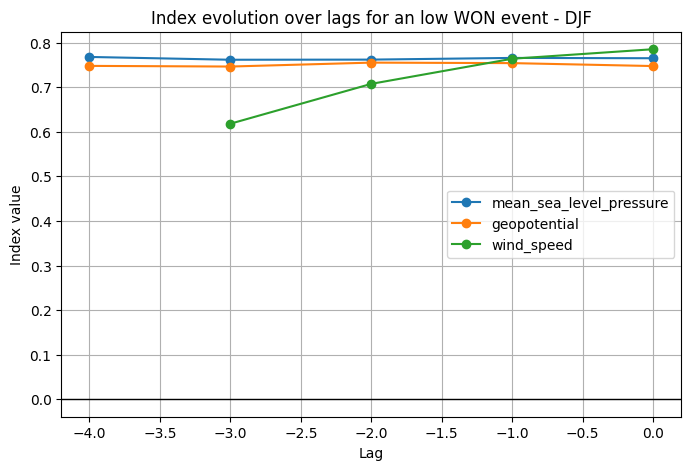

In [ ]:
ds = CV_ROC_AUC  # dein xarray.Dataset

lags = list(range(-4, 1))
variables = ["mean_sea_level_pressure", "geopotential", "wind_speed"]

fig, ax = plt.subplots(figsize=(8, 5))

for var in variables:
    values = []

    for lag in lags:
        if lag==-4 and var=='wind_speed':# or lag==-3 and var=='geopotential':
            continue
        da = ds[f"{var}_index_val1_lag{lag}"]
        values.append(da.item())
    if var=='wind_speed' :#or var=='geopotential':
        lags_plot = [-3,-2, -1, 0]
    else:        lags_plot = lags
    ax.plot(lags_plot, values, marker='o', label=var)

ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel("Lag")
ax.set_ylabel("Index value")
ax.set_title("Index evolution over lags for an low WON event - DJF")
ax.legend()
ax.grid(True)
plt.savefig(f"fig/index_computation/{energy_entry.name}/index_evolution_lags{lags}_{energy_entry.name}_{extreme_event}_DJF.png", dpi=300)
plt.show()

## Prediction Test alle lags einzeln: Test Data Set

In [ ]:
IG = IndexGenerator()

In [ ]:
data_vars = ['mean_sea_level_pressure']#, 'geopotential', 'wind_speed'] mean_sea_level_pressure
var_name = data_vars[0]
training_predictor_partial = training_predictor[var_name]
test_predictor_partial = test_predictor[var_name]
masked_composite_partial = masked_composite[[var_name]]

In [ ]:
roc_list = []
ks_results = []

lags_plot = [-4,-3,-2,-1, 0] #-4,-3,-2,-1, 


for lag_id in lags_plot:
    print(f"Processing lag {lag_id}...")
    # berechne indice mit trainings set
    index_slices=[dict(index_val=1,lag=lag_id)]
    indices=IG.generate(masked_composite_partial,training_predictor_partial,dim='time',slices=index_slices)
    print(indices.data_vars)

    # bekomme indice einstellung
    standardisation_params=IG.get_standardisation_params()
    ixmean=standardisation_params.sel(param='mean')
    ixstd=standardisation_params.sel(param='std')

    # berechne test index
    test_index=IG.generate(masked_composite_partial,test_predictor_partial,dim='time',slices=index_slices, ix_means=ixmean,ix_stds=ixstd)
    # berechne test index ohne standardisierung
    test_index_v2=IG.generate(masked_composite_partial,test_predictor_partial, dim='time',slices=index_slices)

    print("Indices computed for both methods. Now plotting comparisons...")
    print(test_index.data_vars)
    print(test_index_v2.data_vars)

    # # vergleiche beide miteinander
    # for var in data_vars:
    #     da_plot = test_index[f"{var}_index_val1_lag{lag_id}"]
    #     da2_plot = test_index_v2[f"{var}_index_val1_lag{lag_id}"]
    #     plt.scatter(da_plot,da2_plot)
    #     plt.plot(da_plot,da_plot,color='k')
    #     plt.gca().set_xlabel('Standardised with training index params')
    #     plt.gca().set_ylabel('Standardised with test index directly')
    #     plt.title(f"Comparison of standardisation methods for {var} - lag {lag_id}")
    #     plt.savefig(f"fig/index_computation/{energy_entry.name}/{extreme_event}/standardisation_comparison_{var}_lag{lag_id}.png", dpi=300, bbox_inches="tight")
    #     plt.close()
    
    # # plotte Boxplots für Event vs Non-Event (nur eine Variable)

    # fig, ax = plt.subplots(figsize=(6, 4))

    # ax.boxplot(
    #     test_index[f'{var_name}_index_val1_lag{lag_id}'][test_event == 0].values,
    #     whis=[5, 95],
    #     positions=[0],
    #     showfliers=False
    # )

    # ax.boxplot(
    #     test_index[f'{var_name}_index_val1_lag{lag_id}'][test_event == 1].values,
    #     whis=[5, 95],
    #     positions=[1],
    #     showfliers=False
    # )

    # ax.set_title(var_name)
    # ax.set_ylabel('Index amplitude')
    # ax.set_xticks([0, 1])
    # ax.set_xticklabels(['Non event', 'Event'])

    # plt.savefig(
    #     f"fig/index_computation/{energy_entry.name}/{extreme_event}/"
    #     f"boxplot_indices_{energy_entry.name}_{extreme_event}_{var_name}_lag{lag_id}_testindex.png",
    #     dpi=300, bbox_inches="tight"
    # )

    # plt.show()
    # plt.close()

    # # plotte trennung der kurven für event vs non-event
    # for var in data_vars:
    #     test_index[f'{var}_index_val1_lag{lag_id}'].where(test_event==0).plot.hist(density=1,label='No event')
    #     p=test_index[f'{var}_index_val1_lag{lag_id}'].where(test_event==1).plot.hist(density=1,alpha=0.7,label='Event')
    #     plt.legend()
    #     plt.title(f"Distribution of {var} index for lag {lag_id}")
    #     plt.savefig(f"fig/index_computation/{energy_entry.name}/{extreme_event}/distribution_{var}_lag{lag_id}_testindex.png", dpi=300, bbox_inches="tight")
    #     plt.close()
    
    # # ks test mit beiden verteilungen
    # x0 = test_index[f'{var}_index_val1_lag{lag_id}'].where(test_event==0).values
    # x1 = test_index[f'{var}_index_val1_lag{lag_id}'].where(test_event==1).values

    # x0 = x0[~np.isnan(x0)]
    # x1 = x1[~np.isnan(x1)]
    # stat, p_value = ks_2samp(x0, x1)

    # print("KS-Statistik:", stat)
    # print("p-value:", p_value)
    # ks_results.append({
    #         "variable": var,
    #         "lag": lag_id,
    #         "ks_stat": stat,
    #         "p_value": p_value
    #     })
    # berechne ROC AUC
    PT=PredictionTest(test_index,test_event)
    CV_ROC_AUC=PT.categorical_prediction('logregression',score='sklearn_roc_auc',cv_method=None,
                                         cv_kwargs=dict(test_pred=test_index,test_targ=test_event))
    print()
    print(CV_ROC_AUC.data_vars)
    for var in data_vars:
        roc_value = CV_ROC_AUC[f"{var}_index_val1_lag{lag_id}"].item()
        roc_list.append({
            "variable": var,
            "lag": lag_id,
            "roc_auc": roc_value
        })

Processing lag -4...
Data variables:
    mean_sea_level_pressure_index_val1_lag-4  (time) float32 11kB -0.7224 ......
Indices computed for both methods. Now plotting comparisons...
Data variables:
    mean_sea_level_pressure_index_val1_lag-4  (time) float64 9kB -1.332 ... 1...
Data variables:
    mean_sea_level_pressure_index_val1_lag-4  (time) float32 4kB -1.563 ... 0...

Data variables:
    mean_sea_level_pressure_index_val1_lag-4  (cv) float64 8B 0.7761
Processing lag -3...
Data variables:
    mean_sea_level_pressure_index_val1_lag-3  (time) float32 11kB -0.8075 ......
Indices computed for both methods. Now plotting comparisons...
Data variables:
    mean_sea_level_pressure_index_val1_lag-3  (time) float64 9kB -1.302 ... 1...
Data variables:
    mean_sea_level_pressure_index_val1_lag-3  (time) float32 4kB -1.535 ... 1...

Data variables:
    mean_sea_level_pressure_index_val1_lag-3  (cv) float64 8B 0.7793
Processing lag -2...
Data variables:
    mean_sea_level_pressure_index_val1_la

In [ ]:
msl_roc_list = roc_list

In [ ]:
roc_list

[{'variable': 'mean_sea_level_pressure',
  'lag': -4,
  'roc_auc': 0.776139264570094},
 {'variable': 'mean_sea_level_pressure',
  'lag': -3,
  'roc_auc': 0.7793257653938769},
 {'variable': 'mean_sea_level_pressure',
  'lag': -2,
  'roc_auc': 0.7848930892763384},
 {'variable': 'mean_sea_level_pressure',
  'lag': -1,
  'roc_auc': 0.8104937265765033},
 {'variable': 'mean_sea_level_pressure',
  'lag': 0,
  'roc_auc': 0.8494740463128927}]

In [ ]:
msl_roc_list


[{'variable': 'mean_sea_level_pressure',
  'lag': -4,
  'roc_auc': 0.776139264570094},
 {'variable': 'mean_sea_level_pressure',
  'lag': -3,
  'roc_auc': 0.7793257653938769},
 {'variable': 'mean_sea_level_pressure',
  'lag': -2,
  'roc_auc': 0.7848930892763384},
 {'variable': 'mean_sea_level_pressure',
  'lag': -1,
  'roc_auc': 0.8104937265765033},
 {'variable': 'mean_sea_level_pressure',
  'lag': 0,
  'roc_auc': 0.8494740463128927}]

In [ ]:
ws300_roc_list = roc_list

In [ ]:
z500_roc_list = roc_list

In [ ]:
msl_ks_results = ks_results

In [ ]:
z500_ks_results = ks_results

In [ ]:
ws300_ks_results = ks_results

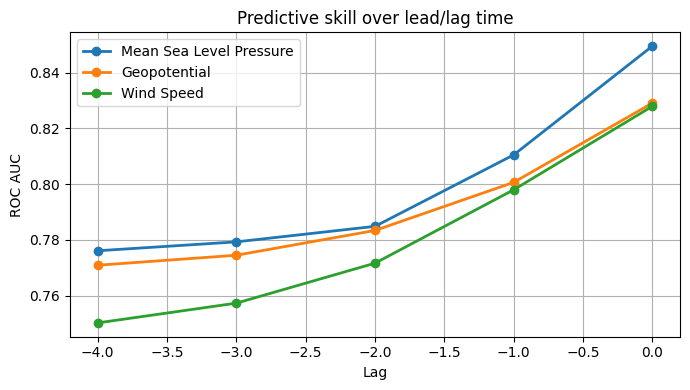

In [ ]:
roc_all = msl_roc_list + z500_roc_list + ws300_roc_list
roc_df = pd.DataFrame(roc_all)

fig, ax = plt.subplots(figsize=(7,4))

for var in roc_df["variable"].unique():

    sub = roc_df[roc_df["variable"] == var].sort_values("lag")

    ax.plot(
        sub["lag"],
        sub["roc_auc"],
        marker="o",
        linewidth=2,
        label=var.replace("_", " ").title()
    )

ax.set_xlabel("Lag")
ax.set_ylabel("ROC AUC")
ax.set_title("Predictive skill over lead/lag time")

ax.legend()
# ax.invert_xaxis()  # optional, aber oft sinnvoll bei Lead-Lag
plt.grid()
plt.tight_layout()
plt.savefig(f"fig/index_computation/{energy_entry.name}/{extreme_event}/roc_auc_over_lags_{energy_entry.name}_{extreme_event}_DJF_anom_testindex.png", dpi=300)
plt.show()

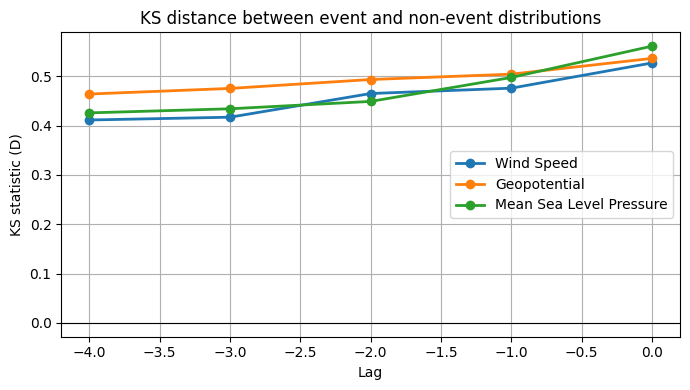

In [ ]:
ks_all = ws300_ks_results + z500_ks_results + msl_ks_results

ks_df = pd.DataFrame(ks_all)

fig, ax = plt.subplots(figsize=(7,4))

for var in ks_df["variable"].unique():

    subset = ks_df[ks_df["variable"] == var]

    ax.plot(
        subset["lag"],
        subset["ks_stat"],
        marker='o',
        linewidth=2,
        label=var.replace("_", " ").title()
    )

ax.axhline(0, color='black', linewidth=0.8)

ax.set_xlabel("Lag")
ax.set_ylabel("KS statistic (D)")
ax.set_title("KS distance between event and non-event distributions")

ax.legend()

plt.grid()
plt.tight_layout()
plt.savefig(f"fig/index_computation/{energy_entry.name}/{extreme_event}/ks_statistics_lags{lags_plot}_{energy_entry.name}_{extreme_event}_DJF_anom_testindex.png", dpi=300)
plt.show()

Processing lag -4...
Processing lag -3...
Processing lag -2...
Processing lag -1...
Processing lag 0...


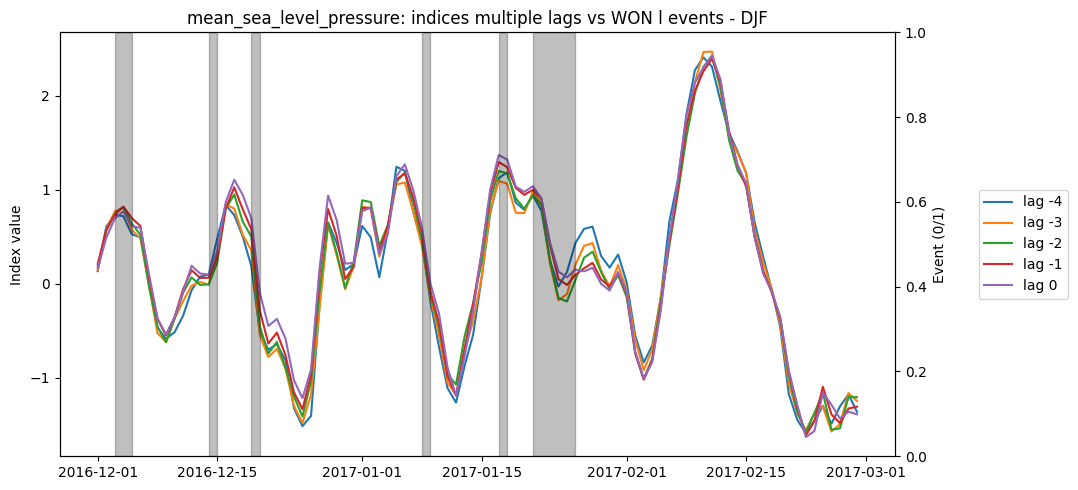

In [ ]:
lags_plot = [-4, -3, -2, -1, 0] #-4, -3, -2, 
var = var_name

index_dict = {}  # hier speichern wir alle Ergebnisse
for lag_id in lags_plot:
    
    print(f"Processing lag {lag_id}...")

    index_slices = [dict(index_val=1, lag=lag_id)]

    # TRAINING (für Standardisierung)
    indices = IG.generate(
        masked_composite_partial,
        training_predictor_partial,
        dim="time",
        slices=index_slices
    )

    # Standardisierung
    standardisation_params = IG.get_standardisation_params()
    ixmean = standardisation_params.sel(param="mean")
    ixstd  = standardisation_params.sel(param="std")

    # TEST INDEX (standardisiert)
    test_index = IG.generate(
        masked_composite_partial,
        test_predictor_partial,
        dim="time",
        slices=index_slices,
        ix_means=ixmean,
        ix_stds=ixstd
    )

    # speichern
    index_dict[lag_id] = test_index

start = "2016-12-01"
end   = "2017-02-28"
time = test_index.time.values
time_mask = (time >= np.datetime64(start)) & (time <= np.datetime64(end))
event = test_event.values[time_mask]
t = test_index.time.values[time_mask]

fig, ax1 = plt.subplots(figsize=(12,5))
ax2 = ax1.twinx()

for lag_id in lags_plot:

    series = index_dict[lag_id][f"{var}_index_val1_lag{lag_id}"].values

    ax1.plot(
        t,
        series[time_mask],
        label=f"lag {lag_id}"
    )


def get_event_blocks(t, event):
    event = event.astype(int)

    blocks = []
    start = None

    for i in range(len(event)):
        if event[i] == 1 and start is None:
            start = t[i]

        if event[i] == 0 and start is not None:
            end = t[i]
            blocks.append((start, end))
            start = None

    # falls Serie mit Event endet
    if start is not None:
        blocks.append((start, t[-1]))

    return blocks
event_blocks = get_event_blocks(t, event)
for start, end in event_blocks:
    ax2.axvspan(
        start,
        end,
        color="black",
        alpha=0.25
    )

# ax2.fill_between(t,0,event,where=(event > 0),step="pre",color="black",alpha=0.75,label="Event")
ax1.set_ylabel("Index value")
ax2.set_ylabel("Event (0/1)")

ax1.set_title(f"{var}: indices multiple lags vs WON {extreme_event} events - DJF")

ax1.legend(
    loc="center left",
    bbox_to_anchor=(1.1, 0.5),
    borderaxespad=0
)
# ax2.legend(loc="upper right")

plt.tight_layout()
plt.subplots_adjust(right=0.75)
plt.savefig(f"fig/index_computation/{energy_entry.name}/{extreme_event}/index_multiple_lags_{var}_{energy_entry.name}_{extreme_event}_DJF_testindex_{str(start)[:4]}_{str(end)[:4]}.png", dpi=300, bbox_inches="tight")
plt.show()

Processing lag -4...
Processing lag -3...
Processing lag -2...
Processing lag -1...
Processing lag 0...


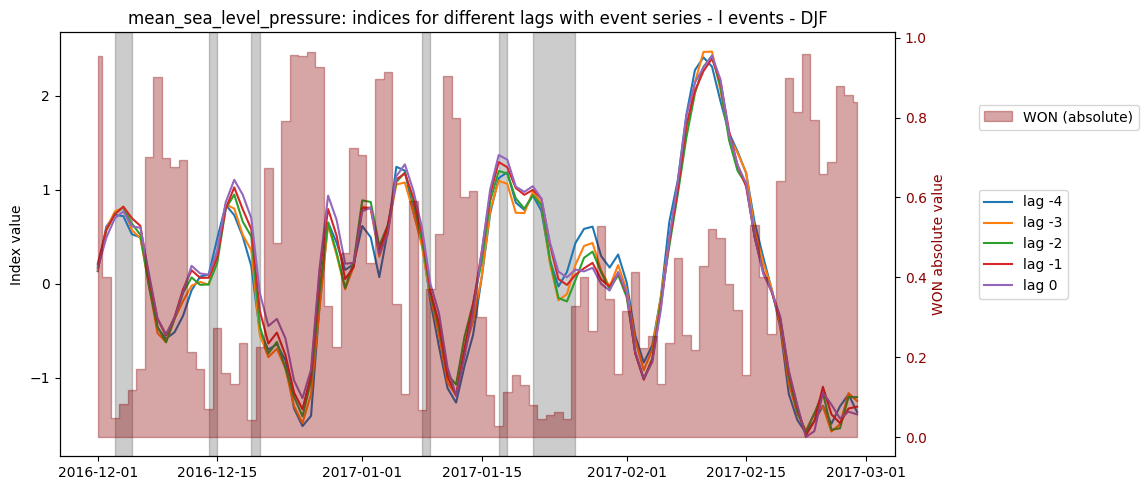

In [ ]:
lags_plot = [-4, -3, -2, -1, 0]
var = var_name

index_dict = {}

# =========================
# 1. INDEX BERECHNUNG
# =========================
for lag_id in lags_plot:
    
    print(f"Processing lag {lag_id}...")

    index_slices = [dict(index_val=1, lag=lag_id)]

    indices = IG.generate(
        masked_composite_partial,
        training_predictor_partial,
        dim="time",
        slices=index_slices
    )

    standardisation_params = IG.get_standardisation_params()
    ixmean = standardisation_params.sel(param="mean")
    ixstd  = standardisation_params.sel(param="std")

    test_index = IG.generate(
        masked_composite_partial,
        test_predictor_partial,
        dim="time",
        slices=index_slices,
        ix_means=ixmean,
        ix_stds=ixstd
    )

    index_dict[lag_id] = test_index


# =========================
# 2. ZEITRAUM
# =========================
start = "2016-12-01"
end   = "2017-02-28"

time = test_index.time.values
time_mask = (time >= np.datetime64(start)) & (time <= np.datetime64(end))

t = time[time_mask]
event = test_event.values[time_mask]

# 👉 NEU: WON (absolute value)
event_abs_aligned = event_abs.sel(time=test_index.time)
won = event_abs_aligned.values[time_mask]


# =========================
# 3. PLOT
# =========================
fig, ax1 = plt.subplots(figsize=(12,5))
ax2 = ax1.twinx()  # WON Achse

# =========================
# 4. INDEX LINIEN
# =========================
for lag_id in lags_plot:

    series = index_dict[lag_id][f"{var}_index_val1_lag{lag_id}"].values

    ax1.plot(
        t,
        series[time_mask],
        label=f"lag {lag_id}"
    )

ax1.set_ylabel("Index value")


# =========================
# 5. WON (rechte Achse)
# =========================
ax2.fill_between(
    t,
    0,
    won,
    color="darkred",
    alpha=0.35,
    step="mid",
    label="WON (absolute)"
)

ax2.set_ylabel("WON absolute value", color="darkred")
ax2.tick_params(axis='y', labelcolor="darkred")


# =========================
# 6. EVENTS als BALKEN
# =========================
def get_event_blocks(t, event):
    event = event.astype(int)

    blocks = []
    start = None

    for i in range(len(event)):
        if event[i] == 1 and start is None:
            start = t[i]

        if event[i] == 0 and start is not None:
            blocks.append((start, t[i]))
            start = None

    if start is not None:
        blocks.append((start, t[-1]))

    return blocks


event_blocks = get_event_blocks(t, event)

for start_b, end_b in event_blocks:
    ax1.axvspan(
        start_b,
        end_b,
        color="black",
        alpha=0.2
    )


# =========================
# 7. TITEL + LEGENDEN
# =========================
ax1.set_title(f"{var}: indices for different lags with event series - {extreme_event} events - DJF")

ax1.legend(
    loc="center left",
    bbox_to_anchor=(1.1, 0.5),
    borderaxespad=0
)

ax2.legend(
    loc="center left",
    bbox_to_anchor=(1.1, 0.8),
    borderaxespad=0
)

# =========================
# 8. LAYOUT + SAVE
# =========================
plt.tight_layout()
plt.subplots_adjust(right=0.75)

plt.savefig(
    f"fig/index_computation/{energy_entry.name}/{extreme_event}/"
    f"index_multiple_lags_{var}_{energy_entry.name}_{extreme_event}_DJF_testindex_with_WON_{str(start)[:4]}_{str(end)[:4]}.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
variables = [
    "mean_sea_level_pressure",
    "geopotential",
    "wind_speed"
]

lag_id = 0

index_dict = {}

for var in variables:

    print(f"Processing {var}")

    var_name = var
    training_predictor_partial = training_predictor[var_name]
    test_predictor_partial = test_predictor[var_name]
    masked_composite_partial = masked_composite[[var_name]]

    index_slices = [dict(index_val=1, lag=lag_id)]

    # Training
    indices = IG.generate(
        masked_composite_partial,
        training_predictor_partial,
        dim="time",
        slices=index_slices
    )

    # Standardisierung
    params = IG.get_standardisation_params()
    ixmean = params.sel(param="mean")
    ixstd  = params.sel(param="std")

    # Test
    test_index = IG.generate(
        masked_composite_partial,
        test_predictor_partial,
        dim="time",
        slices=index_slices,
        ix_means=ixmean,
        ix_stds=ixstd
    )

    index_dict[var] = test_index

Processing mean_sea_level_pressure
<xarray.DataArray 'mean_sea_level_pressure' (time: 1083, latitude: 289,
                                             longitude: 561)> Size: 702MB
array([[[ -184.01562 ,  -183.41406 ,  -182.63281 , ...,  1950.4609  ,
          1947.4844  ,  1944.5     ],
        [ -199.99219 ,  -199.84375 ,  -199.77344 , ...,  1945.9844  ,
          1942.7578  ,  1939.4922  ],
        [ -211.78906 ,  -211.59375 ,  -211.50781 , ...,  1938.5234  ,
          1935.1406  ,  1931.8516  ],
        ...,
        [ -120.21094 ,  -121.07031 ,  -120.14844 , ...,  -117.859375,
          -115.75    ,  -114.27344 ],
        [ -117.59375 ,  -116.69531 ,  -116.21094 , ...,  -116.6875  ,
          -115.97656 ,  -114.      ],
        [ -115.03125 ,  -114.65625 ,  -114.65625 , ...,  -112.32031 ,
          -110.046875,  -108.375   ]],

       [[-1188.9453  , -1190.3359  , -1191.7422  , ...,  1143.3906  ,
          1142.2109  ,  1141.1641  ],
        [-1129.7734  , -1131.8281  , -1134.0234 

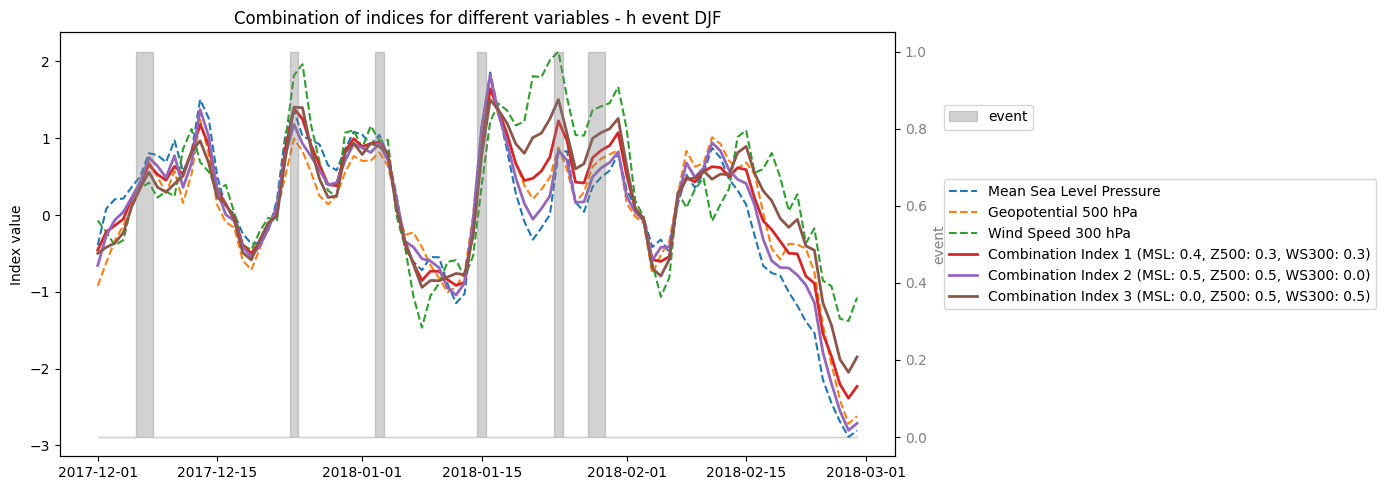

In [ ]:
start = "2017-12-01"
end   = "2018-02-28"

time = test_index.time.values
time_mask = (time >= np.datetime64(start)) & (time <= np.datetime64(end))

t = time[time_mask]

# =========================
# INDIZES
# =========================
mslp = index_dict["mean_sea_level_pressure"][
    f"mean_sea_level_pressure_index_val1_lag{lag_id}"
].values

geo = index_dict["geopotential"][
    f"geopotential_index_val1_lag{lag_id}"
].values

wind = index_dict["wind_speed"][
    f"wind_speed_index_val1_lag{lag_id}"
].values

# =========================
# COMPOSITE
# =========================
w_mslp = 0.4
w_geo  = 0.3
w_wind = 0.3

composite_index = (
    w_mslp * mslp +
    w_geo  * geo +
    w_wind * wind
)

w_mslp2 = 0.5
w_geo2  = 0.5
w_wind2 = 0.0

composite_index2 = (
    w_mslp2 * mslp +
    w_geo2  * geo +
    w_wind2 * wind
)

w_mslp3 = 0.0
w_geo3  = 0.5
w_wind3 = 0.5

composite_index3 = (
    w_mslp3 * mslp +
    w_geo3  * geo +
    w_wind3 * wind
)

# =========================
# WON EVENT
# =========================
event_abs_aligned = test_event.sel(time=test_index.time)
won = event_abs_aligned.values[time_mask]

# =========================
# PLOT
# =========================
fig, ax1 = plt.subplots(figsize=(12,5))
ax2 = ax1.twinx()

# --- Indices ---
ax1.plot(t, mslp[time_mask], label="Mean Sea Level Pressure", linestyle="--")
ax1.plot(t, geo[time_mask], label="Geopotential 500 hPa", linestyle="--")
ax1.plot(t, wind[time_mask], label="Wind Speed 300 hPa", linestyle="--")
ax1.plot(t, composite_index[time_mask], label=f"Combination Index 1 (MSL: {w_mslp}, Z500: {w_geo}, WS300: {w_wind})", linewidth=2)
ax1.plot(t, composite_index2[time_mask], label=f"Combination Index 2 (MSL: {w_mslp2}, Z500: {w_geo2}, WS300: {w_wind2})", linewidth=2)
ax1.plot(t, composite_index3[time_mask], label=f"Combination Index 3 (MSL: {w_mslp3}, Z500: {w_geo3}, WS300: {w_wind3})", linewidth=2)

ax1.set_ylabel("Index value")

# --- WON als Balken ---
ax2.fill_between(
    t,
    0,
    won,
    color="grey",
    alpha=0.35,
    step="mid",
    label="event"
)

ax2.set_ylabel("event", color="grey")
ax2.tick_params(axis='y', labelcolor="grey")

# =========================
# TITEL + LEGEND
# =========================
ax1.set_title(f"Combination of indices for different variables - {extreme_event} event DJF")

ax1.legend(
    loc="center left",
    bbox_to_anchor=(1.05, 0.5)
)

ax2.legend(
    loc="center left",
    bbox_to_anchor=(1.05, 0.8)
)

# =========================
# LAYOUT
# =========================
plt.tight_layout()
plt.subplots_adjust(right=0.75)
plt.savefig(f"fig/index_computation/{energy_entry.name}/{extreme_event}/composite_index_combination_lag{lag_id}_{energy_entry.name}_{extreme_event}_DJF_testindex_{str(start)[:4]}_{str(end)[:4]}.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
mean_msl = ds_msl["mean_sea_level_pressure"].mean()
std_msl  = ds_msl["mean_sea_level_pressure"].std()
print(f"MSL - Mean: {mean_msl.values}, Std: {std_msl.values}")

MSL - Mean: -1.621653437614441, Std: 1060.60205078125


In [ ]:
mean_msl = ds_z500["geopotential"].mean()
std_msl  = ds_z500["geopotential"].std()
print(f"Geopotential - Mean: {mean_msl.values}, Std: {std_msl.values}")

Geopotential - Mean: -12.112702369689941, Std: 1174.6710205078125


In [ ]:
mean_ws = ds_ws["wind_speed"].mean()
std_ws  = ds_ws["wind_speed"].std()
print(f"Wind Speed - Mean: {mean_ws.values}, Std: {std_ws.values}")

Wind Speed - Mean: 0.02495148591697216, Std: 9.736943244934082


## Pangu test

In [ ]:
BASE_PATH = Path("data/ERA5/")
INPUT_PATH = BASE_PATH / f"mean_sea_level_pressure"

files = sorted(INPUT_PATH.glob("era5_daily_*.nc"))
years = sorted(list(set([f.name.split("_")[-1][:4] for f in files])))

print("[INFO] Years:", years)

# -----------------------------------
# 1. GLOBALE KLIMATOLOGIE BERECHNEN
# -----------------------------------
print("[INFO] Computing climatology...")

ds_all = xr.open_mfdataset(
    files,
    combine="by_coords",
    chunks={"time": -1}
).sortby("time")

# Mittelwert pro Kalendertag
clim = ds_all.groupby("time.dayofyear").mean("time")

# 30-Tage-Glättung der Klimatologie
clim_smooth = clim.rolling(
    dayofyear=30,
    center=True,
    min_periods=15
).mean()

ds_all.close()
del ds_all

# lade era5 data um differenz zu bilden
era5_msl = clim_smooth.copy()
era5_msl = era5_msl.assign_coords(
    longitude=((era5_msl.longitude + 180) % 360) - 180
).sortby("longitude")

[INFO] Years: ['1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022']
[INFO] Computing climatology...


In [ ]:
# wie funktionieren die indices in den pangu daten?
import gcsfs
fs = gcsfs.GCSFileSystem(token="anon")

ds_pangu = xr.open_zarr(
    "gs://weatherbench2/datasets/pangu/2018-2022_0012_0p25.zarr",
    consolidated=True,
    storage_options={"token": "anon"}
)
pangu_msl = ds_pangu['mean_sea_level_pressure'].sel(time=slice('2022-12-01', '2022-12-18'), latitude=slice(84,12)).load() # dunkelflaute
# pangu_msl = ds_pangu.wind_speed.sel(time=slice('2022-02-10', '2022-02-25'), latitude=slice(84,12), level=300).load() #zeynep
# lade era5 als climatology für index generation
# berechne era5 clim: mean über gesamten zeitraum, 30 d running mean

In [ ]:
dates = pd.date_range('2022-12-01', '2022-12-11')#('2022-02-10', '2022-02-20')#("2022-12-01", "2022-12-11")
doy = dates.dayofyear
print(doy)

Index([335, 336, 337, 338, 339, 340, 341, 342, 343, 344, 345], dtype='int32')


In [ ]:
# select zeitraum aus era5
era5_msl_djf = clim_smooth.sel(dayofyear=doy)

# bilde pangu tagesmittelwert
pangu_msl1 = pangu_msl[0,:,:,:]
# Stunden → timedelta64[h]
lead = pangu_msl1.prediction_timedelta * np.timedelta64(1, "h")
# neue Zeitkoordinate
valid_time = pangu_msl1.time + lead
# zuweisen
pangu_msl1 = pangu_msl1.assign_coords(valid_time=("prediction_timedelta", valid_time.values)).swap_dims({"prediction_timedelta": "valid_time"})
# mitteln
daily_mean_pangu_msl = pangu_msl1.resample(valid_time="1D").mean()

In [ ]:
era5_aligned = era5_msl_djf.sel(dayofyear=doy.values)
era5_aligned = era5_aligned.rename({"dayofyear": "valid_time"})
era5_aligned = era5_aligned.assign_coords(valid_time=daily_mean_pangu_msl.valid_time)

In [ ]:
diff = daily_mean_pangu_msl - era5_aligned

In [ ]:
diff = diff.assign_coords(
    longitude=((diff.longitude + 180) % 360) - 180
).sortby("longitude")

In [ ]:
selected_composite_passtern = masked_composite['mean_sea_level_pressure'].sel(index_val=1, lag=0).to_dataset()

In [ ]:
forecast_predictor = diff
forecast_index=IG.generate(selected_composite_passtern,forecast_predictor,dim='valid_time',ix_means=ixmean,ix_stds=ixstd)

In [ ]:
print(
    selected_composite_passtern
    .to_array()
    .notnull()
    .sum()
    .item()
)

130042


In [ ]:
valid_overlap = (
    selected_composite_passtern["mean_sea_level_pressure"].notnull()
    &
    forecast_predictor["mean_sea_level_pressure"].isel(valid_time=0).notnull()
)

print(valid_overlap.sum().compute().item())

130042
